# Analyse Exploratoire

> Ce notebook reprend **à l'identique** le périmètre, le nettoyage et le feature engineering du notebook 1. Seule la cible change : `TotalGHGEmissions` au lieu de `SiteEnergyUseWN(kBtu)`.

### Import des modules

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
from scipy.stats import loguniform
from sklearn.inspection import permutation_importance
from scipy.stats import uniform

pd.set_option('display.max_columns', None)

Les chemins sont résolus depuis la racine du projet : le notebook s'exécute indifféremment depuis `notebooks/` ou depuis la racine du dépôt.

In [2]:
# =========================================================
# Chemins du projet (robustes au repertoire d'execution)
# =========================================================
import sys
from pathlib import Path

# racine du projet : on remonte d'un niveau si on execute depuis notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_RAW = PROJECT_ROOT / "data" / "raw"        # jeu de donnees source
FIG_DIR = PROJECT_ROOT / "reports" / "figures"  # sorties graphiques
FIG_DIR.mkdir(parents=True, exist_ok=True)

# rend le module de fonctions (src/) importable depuis le notebook
sys.path.insert(0, str(PROJECT_ROOT / "src"))


## Partie 1 : Analyse Exploratoire

#### Chargement des données

Relevés de consommation et d'émissions 2016 de la ville de Seattle.

In [3]:
building_consumption = pd.read_csv(DATA_RAW / "2016_Building_Energy_Benchmarking.csv")

#### Premier aperçu

Structure d'une ligne, volumétrie, types et taux de valeurs manquantes par colonne.

In [4]:
# On regarde comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [5]:
building_consumption.shape

(3376, 46)

In [6]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

In [7]:
# On regarde le % dse valeurs manquantes par colonne
building_consumption.isna().mean()*100

OSEBuildingID                        0.000000
DataYear                             0.000000
BuildingType                         0.000000
PrimaryPropertyType                  0.000000
PropertyName                         0.000000
Address                              0.000000
City                                 0.000000
State                                0.000000
ZipCode                              0.473934
TaxParcelIdentificationNumber        0.000000
CouncilDistrictCode                  0.000000
Neighborhood                         0.000000
Latitude                             0.000000
Longitude                            0.000000
YearBuilt                            0.000000
NumberofBuildings                    0.236967
NumberofFloors                       0.000000
PropertyGFATotal                     0.000000
PropertyGFAParking                   0.000000
PropertyGFABuilding(s)               0.000000
ListOfAllPropertyUseTypes            0.266588
LargestPropertyUseType            

In [8]:
# Analyse des types de bâtiments
building_consumption['BuildingType'].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

#### Répartition des usages et des quartiers

On inspecte les modalités de `PrimaryPropertyType` et `Neighborhood` pour repérer les catégories à regrouper.

In [9]:
building_consumption['PrimaryPropertyType'].value_counts()

PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily          105
Retail Store                    91
Hotel                           77
Worship Facility                71
Distribution Center             53
Senior Care Community           45
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      25
Residence Hall                  23
Restaurant                      12
Refrigerated Warehouse          12
Hospital                        10
Laboratory                      10
Office                           3
Name: count, dtype: int64

In [10]:
#cols = ['LargestPropertyUseType','SecondLargestPropertyUseType']
#building_consumption[cols].groupby(cols).size()

In [11]:
building_consumption['Neighborhood'].value_counts()

Neighborhood
DOWNTOWN                  573
EAST                      453
MAGNOLIA / QUEEN ANNE     423
GREATER DUWAMISH          375
NORTHEAST                 280
LAKE UNION                251
NORTHWEST                 210
SOUTHWEST                 166
NORTH                     145
BALLARD                   126
CENTRAL                   107
SOUTHEAST                  95
DELRIDGE                   80
North                      42
Central                    27
Northwest                  11
Ballard                     7
Delridge                    4
DELRIDGE NEIGHBORHOODS      1
Name: count, dtype: int64

#### Les colonnes retenues : 
     PrimaryPropertyType
     Neighborhood
     NumberofBuildings                   
     NumberofFloors
     LargestPropertyUseType (à supprimer dans un premier temps)
     YearBuilt 
     PropertyGFATotal
     PropertyGFAParking
     PropertyGFABuilding(s)
     Electricity(kBtu)
     NaturalGas(kBtu)
     
#### La target retenue : 
     SiteEnergyUseWN(kBtu)

In [12]:
features = ['PrimaryPropertyType',
            'BuildingType',
            'Neighborhood',
            'NumberofBuildings',                   
            'NumberofFloors',
            'YearBuilt',
            'PropertyGFATotal',
            'PropertyGFAParking',
            'PropertyGFABuilding(s)',
            'Electricity(kBtu)',
            'NaturalGas(kBtu)',
            'LargestPropertyUseType',
            'LargestPropertyUseTypeGFA',
            'SecondLargestPropertyUseType',
            'SecondLargestPropertyUseTypeGFA',
            'ThirdLargestPropertyUseType',
            'ThirdLargestPropertyUseTypeGFA',
            'SiteEnergyUse(kBtu)',
            'TotalGHGEmissions']

In [13]:
building_consumption_NR = building_consumption[features]
building_consumption_NR.head()

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.0,NaN,NaN,NaN,NaN,7226362.5,249.98
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,295.86
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,49526664.0,1493800.0,Hotel,756493.0,NaN,NaN,NaN,NaN,72587024.0,2089.28
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2768924.0,1811213.0,Hotel,61320.0,NaN,NaN,NaN,NaN,6794584.0,286.43
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5368607.0,8803998.0,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,505.01


Première variable construite : le nombre de types d'usage déclarés par bâtiment, extrait de `ListOfAllPropertyUseTypes`.

In [14]:
building_consumption_NR['nb_property_use_types'] = (building_consumption['ListOfAllPropertyUseTypes'].str.split(',').apply(lambda x: len(x) if isinstance(x, list) else 0))
building_consumption_NR.head()

C:\Users\faiza\AppData\Local\Temp\ipykernel_10764\429724317.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  building_consumption_NR['nb_property_use_types'] = (building_consumption['ListOfAllPropertyUseTypes'].str.split(',').apply(lambda x: len(x) if isinstance(x, list) else 0))


,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.0,NaN,NaN,NaN,NaN,7226362.5,249.98,1
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,295.86,3
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,49526664.0,1493800.0,Hotel,756493.0,NaN,NaN,NaN,NaN,72587024.0,2089.28,1
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2768924.0,1811213.0,Hotel,61320.0,NaN,NaN,NaN,NaN,6794584.0,286.43,1
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5368607.0,8803998.0,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,505.01,3


### Suppression des bâtiments non-résidentiels NR

In [15]:
BuildingTypeNR = ['NonResidential',
                  'SPS-District K-12',
                  'Nonresidential COS',
                  'Campus',
                  'Nonresidential WA']
building_consumption_NR = building_consumption_NR[building_consumption['BuildingType'].isin(BuildingTypeNR)]
building_consumption_NR.shape

(1668, 20)

In [16]:
building_consumption_NR['BuildingType'].value_counts()

BuildingType
NonResidential        1460
SPS-District K-12       98
Nonresidential COS      85
Campus                  24
Nonresidential WA        1
Name: count, dtype: int64

In [17]:
building_consumption_NR['PrimaryPropertyType'].value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Restaurant                      12
Refrigerated Warehouse          12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64

Les bâtiments résidentiels restants sont écartés à trois niveaux : type principal, puis deuxième et troisième usages déclarés.

In [18]:
BuildingPropertyTypeNR = ['Low-Rise Multifamily','Multifamily Housing' ]
building_consumption_NR = building_consumption_NR[~building_consumption_NR['PrimaryPropertyType'].isin(BuildingPropertyTypeNR)]
building_consumption_NR.shape

(1665, 20)

In [19]:
building_consumption_NR = building_consumption_NR[~building_consumption_NR['LargestPropertyUseType'].isin(BuildingPropertyTypeNR)]
building_consumption_NR = building_consumption_NR[~building_consumption_NR['SecondLargestPropertyUseType'].isin(BuildingPropertyTypeNR)]
building_consumption_NR = building_consumption_NR[~building_consumption_NR['ThirdLargestPropertyUseType'].isin(BuildingPropertyTypeNR)]

building_consumption_NR['LargestPropertyUseType'].value_counts()

LargestPropertyUseType
Office                                                  483
Non-Refrigerated Warehouse                              198
K-12 School                                             139
Other                                                    98
Retail Store                                             96
Hotel                                                    75
Worship Facility                                         71
Distribution Center                                      54
Supermarket/Grocery Store                                41
Medical Office                                           41
Other - Recreation                                       31
Parking                                                  28
Self-Storage Facility                                    27
College/University                                       24
Residence Hall/Dormitory                                 21
Other - Entertainment/Public Assembly                    20
Senior Care Commu

In [20]:

building_consumption_NR['SecondLargestPropertyUseType'].value_counts()

SecondLargestPropertyUseType
Parking                                                 327
Office                                                  164
Retail Store                                             83
Other                                                    44
Non-Refrigerated Warehouse                               29
Restaurant                                               29
Fitness Center/Health Club/Gym                           16
Data Center                                              13
Other - Services                                         11
Laboratory                                                8
Medical Office                                            8
Bank Branch                                               7
Distribution Center                                       7
Supermarket/Grocery Store                                 7
Other - Entertainment/Public Assembly                     6
K-12 School                                               5
Repair Serv

Contrôle de cohérence : part des bâtiments dont les deux premiers usages déclarés sont identiques.

In [21]:
(building_consumption_NR['LargestPropertyUseType'] 
 == building_consumption_NR['SecondLargestPropertyUseType']).mean()*100

np.float64(0.061274509803921566)

In [22]:
building_consumption_NR.shape

(1632, 20)

### Nettoyage des NaN

In [23]:
# affichage du % de NaN de chaque feature
building_consumption_NR.isna().mean()*100

PrimaryPropertyType                 0.000000
BuildingType                        0.000000
Neighborhood                        0.000000
NumberofBuildings                   0.122549
NumberofFloors                      0.000000
YearBuilt                           0.000000
PropertyGFATotal                    0.000000
PropertyGFAParking                  0.000000
PropertyGFABuilding(s)              0.000000
Electricity(kBtu)                   0.122549
NaturalGas(kBtu)                    0.122549
LargestPropertyUseType              0.367647
LargestPropertyUseTypeGFA           0.367647
SecondLargestPropertyUseType       49.754902
SecondLargestPropertyUseTypeGFA    49.754902
ThirdLargestPropertyUseType        80.269608
ThirdLargestPropertyUseTypeGFA     80.269608
SiteEnergyUse(kBtu)                 0.122549
TotalGHGEmissions                   0.122549
nb_property_use_types               0.000000
dtype: float64

In [24]:
# lignes concernées par les NaN
building_consumption_NR[building_consumption_NR.isna().any(axis=1)]

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3.946027e+06,1.276453e+06,Hotel,88434.0,NaN,NaN,NaN,NaN,7.226362e+06,249.98,1
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,4.952666e+07,1.493800e+06,Hotel,756493.0,NaN,NaN,NaN,NaN,7.258702e+07,2089.28,1
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2.768924e+06,1.811213e+06,Hotel,61320.0,NaN,NaN,NaN,NaN,6.794584e+06,286.43,1
5,Other,Nonresidential COS,DOWNTOWN,1.0,2,1999,97288,37198,60090,7.371434e+06,4.715182e+06,Police Station,88830.0,NaN,NaN,NaN,NaN,1.208662e+07,301.81,1
6,Hotel,NonResidential,DOWNTOWN,1.0,11,1926,83008,0,83008,2.811215e+06,2.947580e+06,Hotel,81352.0,NaN,NaN,NaN,NaN,5.758795e+06,176.14,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3367,Other,Nonresidential COS,EAST,1.0,1,1912,23445,0,23445,1.260870e+06,4.715376e+06,Other - Recreation,23445.0,NaN,NaN,NaN,NaN,5.976246e+06,259.22,1
3369,Office,Nonresidential COS,SOUTHEAST,1.0,1,1960,15398,0,15398,2.775369e+05,1.102730e+05,Office,15398.0,NaN,NaN,NaN,NaN,3.878100e+05,7.79,1
3370,Other,Nonresidential COS,DELRIDGE NEIGHBORHOODS,1.0,1,1982,18261,0,18261,6.323620e+05,2.997200e+05,Other - Recreation,18261.0,NaN,NaN,NaN,NaN,9.320821e+05,20.33,1
3371,Office,Nonresidential COS,GREATER DUWAMISH,1.0,1,1990,12294,0,12294,5.242709e+05,3.254750e+05,Office,12294.0,NaN,NaN,NaN,NaN,8.497457e+05,20.94,1


Les bâtiments sans relevé d'émissions sont supprimés : sans cible, ils ne servent ni à l'apprentissage ni à l'évaluation.

In [25]:
# suppression des lignes avec des targets absentes
mask_conso = (building_consumption_NR['TotalGHGEmissions'].notna()) | (building_consumption_NR['TotalGHGEmissions']==0)
building_consumption_NR = building_consumption_NR[mask_conso]

# Utiliser un seuil pour éliminer les bâtiments à très faible consommation (1%), évite d'avoir des valeurs inf aux calculs de % d'énergie
threshold = building_consumption_NR['SiteEnergyUse(kBtu)'].quantile(0.01)
building_consumption_NR = building_consumption_NR[building_consumption_NR['SiteEnergyUse(kBtu)'] > threshold]
# affichage du % de NaN de chaque feature
building_consumption_NR.isna().mean()*100


PrimaryPropertyType                 0.000000
BuildingType                        0.000000
Neighborhood                        0.000000
NumberofBuildings                   0.000000
NumberofFloors                      0.000000
YearBuilt                           0.000000
PropertyGFATotal                    0.000000
PropertyGFAParking                  0.000000
PropertyGFABuilding(s)              0.000000
Electricity(kBtu)                   0.000000
NaturalGas(kBtu)                    0.000000
LargestPropertyUseType              0.247985
LargestPropertyUseTypeGFA           0.247985
SecondLargestPropertyUseType       49.287043
SecondLargestPropertyUseTypeGFA    49.287043
ThirdLargestPropertyUseType        80.037198
ThirdLargestPropertyUseTypeGFA     80.037198
SiteEnergyUse(kBtu)                 0.000000
TotalGHGEmissions                   0.000000
nb_property_use_types               0.000000
dtype: float64

`LargestPropertyUseType` manquant est comblé par `PrimaryPropertyType`, qui porte la même information en moins détaillé.

In [26]:
# traitement du cas 'LargestPropertyUseType'
building_consumption_NR[building_consumption_NR['LargestPropertyUseType'].isna()].head(20)

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types
353,Self-Storage Facility,NonResidential,BALLARD,2.0,2,1946,111445,0,111445,3007514.0,2689958.0,NaN,NaN,NaN,NaN,NaN,NaN,5.697472e+06,163.83,13
1147,Hotel,NonResidential,DOWNTOWN,1.0,8,1910,61721,0,61721,2534592.0,362488.0,NaN,NaN,NaN,NaN,NaN,NaN,2.897080e+06,36.92,1
2414,Small- and Mid-Sized Office,NonResidential,LAKE UNION,1.0,4,2008,48350,0,48350,3168131.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,3.168131e+06,22.09,1
2459,Restaurant,NonResidential,DOWNTOWN,1.0,3,1913,28800,0,28800,402907.0,497017.0,NaN,NaN,NaN,NaN,NaN,NaN,8.999242e+05,29.21,1


In [27]:
# remplir avec les information de 'PrimaryPropertyType'
building_consumption_NR['LargestPropertyUseType'] = (building_consumption_NR['LargestPropertyUseType'].fillna(building_consumption_NR['PrimaryPropertyType']))
building_consumption_NR['LargestPropertyUseTypeGFA'] = (building_consumption_NR['LargestPropertyUseTypeGFA'].fillna(building_consumption_NR['PropertyGFABuilding(s)']))
building_consumption_NR[building_consumption_NR['LargestPropertyUseType'].isna()].head(20)

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types


In [28]:
# affichage du % de NaN de chaque feature
# les NaN dans Second/ThirdLargestPropertyUseType sont gardés, car la colonne 'LargestPropertyUseType' est dans ce cas dominante 

building_consumption_NR.isna().mean()*100

PrimaryPropertyType                 0.000000
BuildingType                        0.000000
Neighborhood                        0.000000
NumberofBuildings                   0.000000
NumberofFloors                      0.000000
YearBuilt                           0.000000
PropertyGFATotal                    0.000000
PropertyGFAParking                  0.000000
PropertyGFABuilding(s)              0.000000
Electricity(kBtu)                   0.000000
NaturalGas(kBtu)                    0.000000
LargestPropertyUseType              0.000000
LargestPropertyUseTypeGFA           0.000000
SecondLargestPropertyUseType       49.287043
SecondLargestPropertyUseTypeGFA    49.287043
ThirdLargestPropertyUseType        80.037198
ThirdLargestPropertyUseTypeGFA     80.037198
SiteEnergyUse(kBtu)                 0.000000
TotalGHGEmissions                   0.000000
nb_property_use_types               0.000000
dtype: float64

Correction des valeurs nulles incohérentes : un bâtiment compte au minimum un étage, un bâtiment et un type d'usage.

In [29]:
# correction des données : 'NumberofBuildings' >= 1 & 'NumberofFloors'>=1 & 'nb_property_use_types' >=1
building_consumption_NR['NumberofBuildings'] = building_consumption_NR['NumberofBuildings'].replace(0, 1)
building_consumption_NR['NumberofFloors'] = building_consumption_NR['NumberofFloors'].replace(0, 1)
building_consumption_NR['nb_property_use_types'] = building_consumption_NR['nb_property_use_types'].replace(0, 1)

building_consumption_NR.shape

(1613, 20)

### Analyse descriptive avec describe()

In [30]:
building_consumption_NR.describe()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types
count,1613.000000,1613.000000,1613.000000,1.613000e+03,1613.000000,1.613000e+03,1.613000e+03,1.613000e+03,1.613000e+03,818.000000,322.000000,1.613000e+03,1613.000000,1613.000000
mean,1.202728,4.117793,1961.945443,1.177660e+05,12857.772474,1.049082e+05,5.919088e+06,1.995622e+06,9.900302e+04,35545.252197,13771.647201,8.572254e+06,188.116249,1.855549
std,2.969730,6.584044,32.479228,2.980259e+05,42401.310897,2.851314e+05,2.110427e+07,9.515644e+06,2.794369e+05,65656.406919,36360.331713,3.069662e+07,763.623218,1.172298
min,1.000000,1.000000,1900.000000,1.128500e+04,0.000000,3.636000e+03,-1.154170e+05,0.000000e+00,5.656000e+03,0.000000,0.000000,2.410550e+04,-0.800000,1.000000
25%,1.000000,1.000000,1930.000000,2.925800e+04,0.000000,2.830400e+04,7.232400e+05,0.000000e+00,2.558000e+04,5098.250000,2477.500000,1.252324e+06,20.460000,1.000000
50%,1.000000,2.000000,1965.000000,4.892400e+04,0.000000,4.680000e+04,1.619177e+06,5.038750e+05,4.392000e+04,11921.500000,5485.500000,2.590622e+06,49.790000,2.000000
75%,1.000000,4.000000,1989.000000,1.040990e+05,0.000000,9.447200e+04,4.897760e+06,1.528541e+06,9.212900e+04,30949.750000,11849.000000,6.960904e+06,144.410000,2.000000
max,111.000000,99.000000,2015.000000,9.320156e+06,512608.000000,9.320156e+06,6.570744e+08,2.979090e+08,9.320156e+06,639931.000000,459748.000000,8.739237e+08,16870.980000,13.000000


Distribution des variables numériques retenues, pour repérer les valeurs extrêmes et les ordres de grandeur très différents.

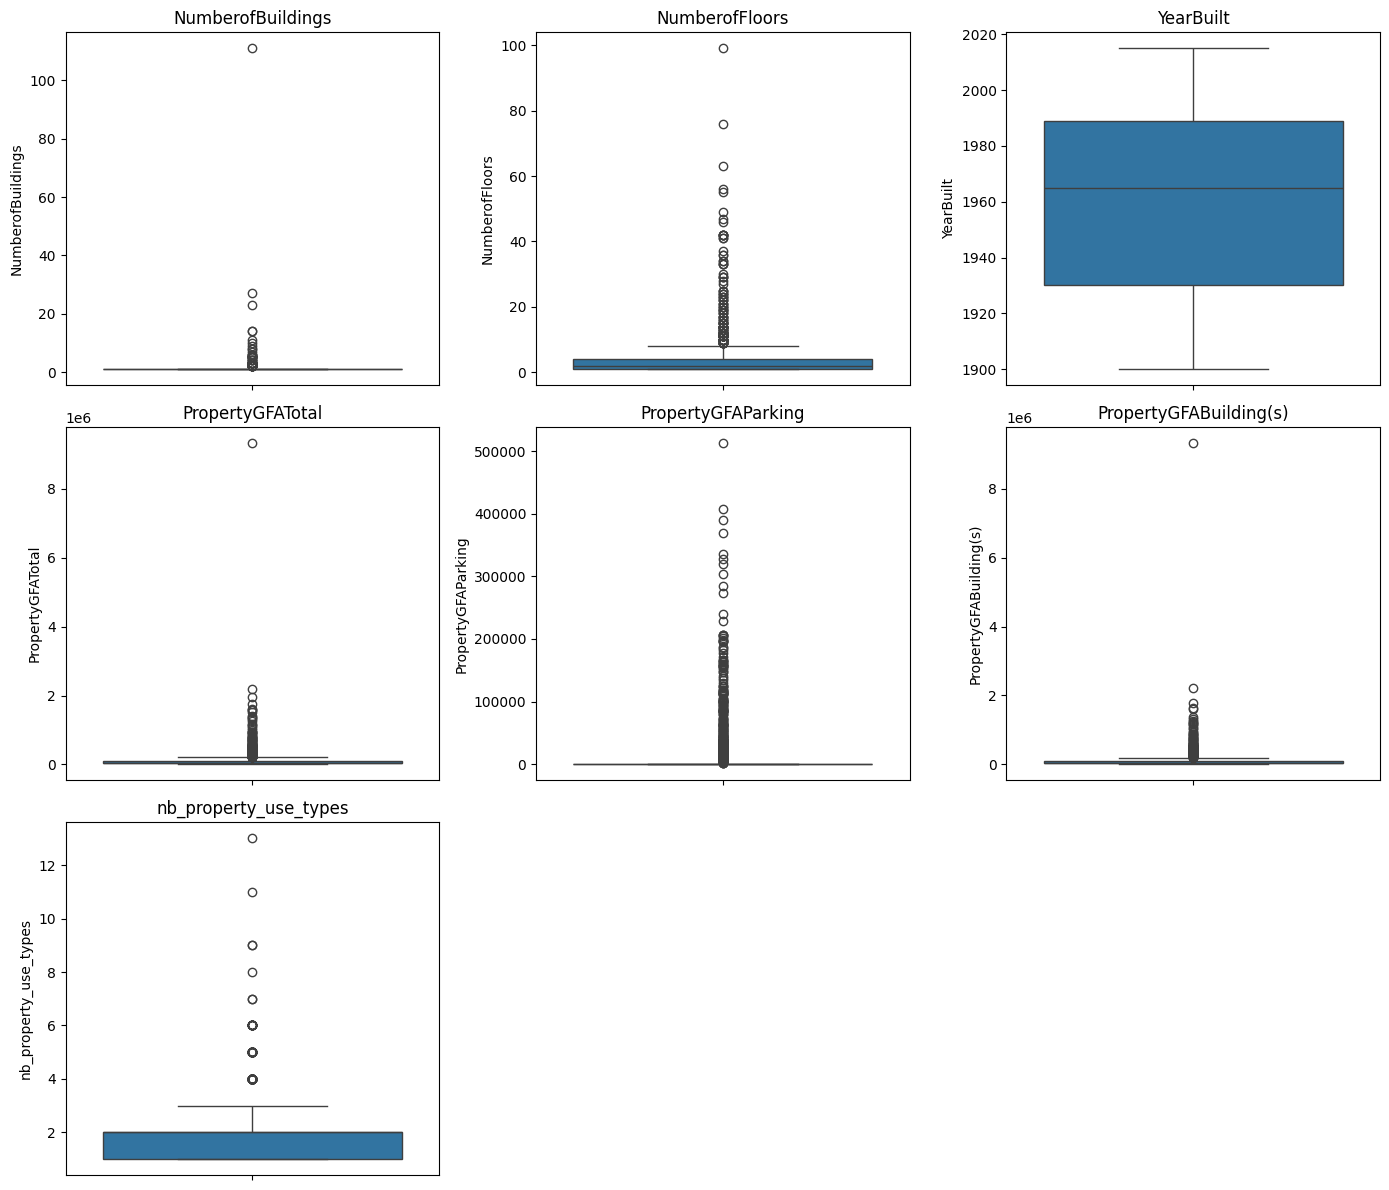

In [31]:
cols_num = [
    'NumberofBuildings',
    'NumberofFloors',
    'YearBuilt',
    'PropertyGFATotal', 
    'PropertyGFAParking', 
    'PropertyGFABuilding(s)', 
    'nb_property_use_types']

nb_colonnes = 3
nb_lignes = len(cols_num)//3+1
plt.figure(figsize=(14,12))
for i, col in enumerate(cols_num, 1):
    plt.subplot(nb_lignes, nb_colonnes, i)
    sns.boxplot(y=building_consumption_NR[col])
    plt.title(col)

plt.tight_layout()
plt.savefig(FIG_DIR / "analyse_descriptive_NR.png", dpi=300)
plt.show()

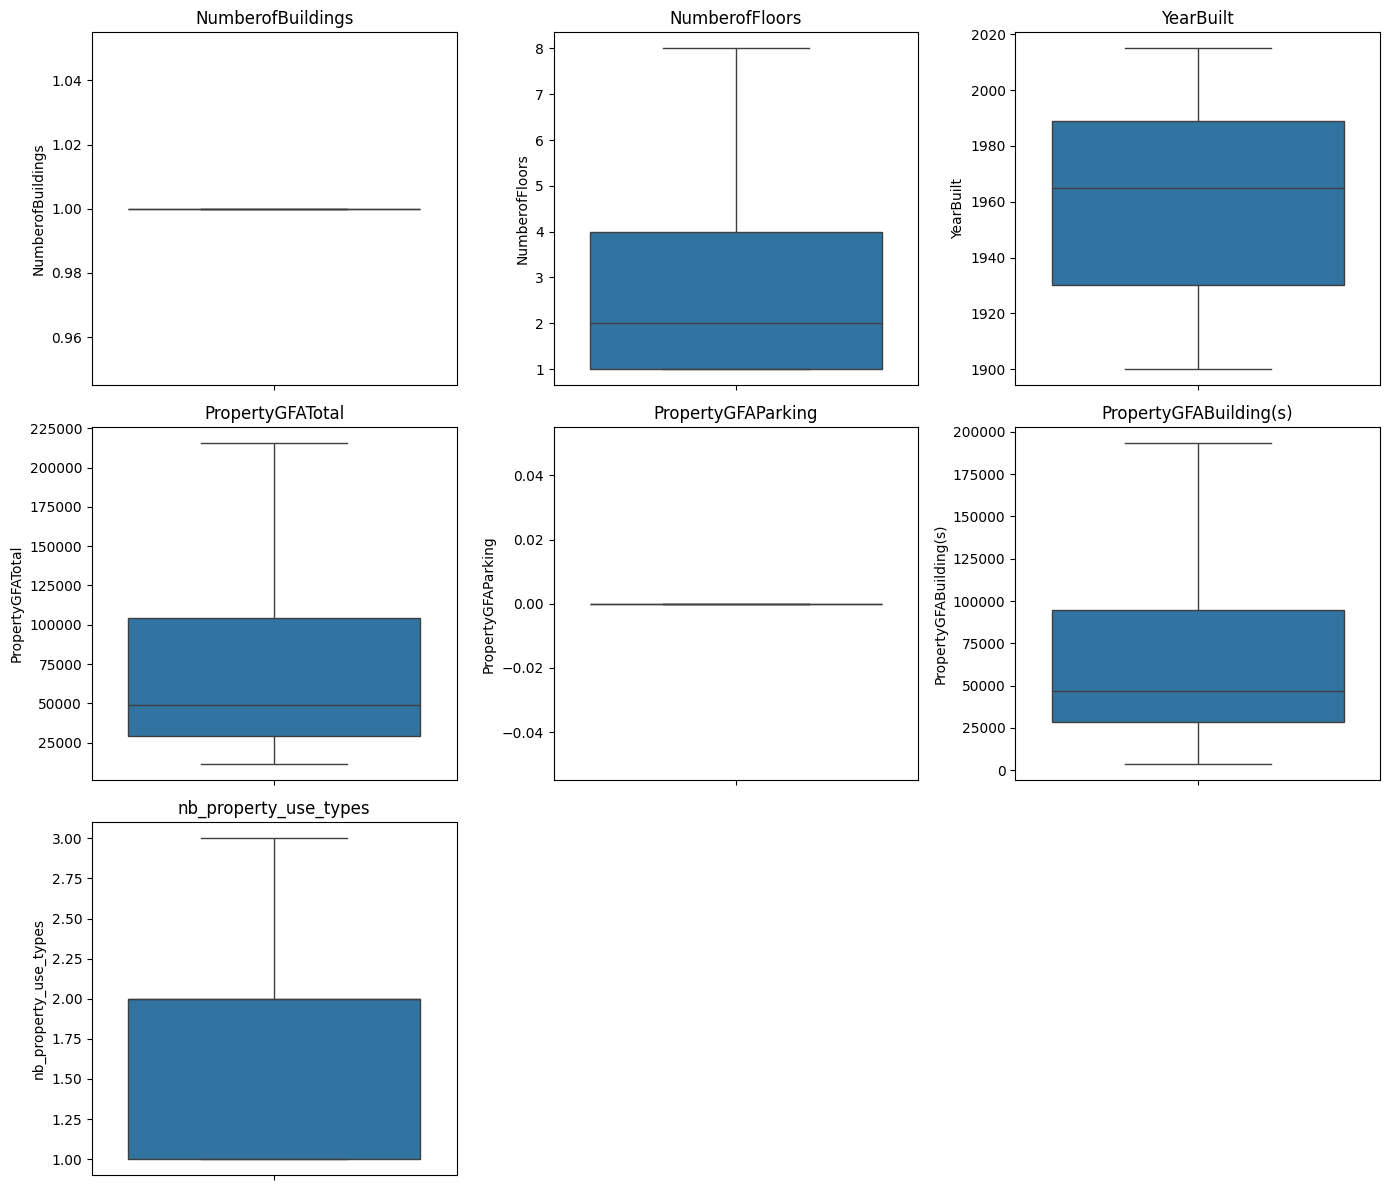

In [32]:
cols_num = [
    'NumberofBuildings',
    'NumberofFloors',
    'YearBuilt',
    'PropertyGFATotal', 
    'PropertyGFAParking', 
    'PropertyGFABuilding(s)', 
    'nb_property_use_types']

nb_colonnes = 3
nb_lignes = len(cols_num)//3+1
plt.figure(figsize=(14,12))
for i, col in enumerate(cols_num, 1):
    plt.subplot(nb_lignes, nb_colonnes, i)
    sns.boxplot(y=building_consumption_NR[col],showfliers=False)
    plt.title(col)

plt.tight_layout()
plt.savefig(FIG_DIR / "analyse_descriptive_NR_zoom.png", dpi=300)
plt.show()

### Différence entre les immeubles mono-usage et multi-usages

In [33]:
building_consumption_NR['usage_type'] = 0
building_consumption_NR.loc[building_consumption_NR['nb_property_use_types'] > 1, 'usage_type'] = 1

building_consumption_NR.head()

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.0,NaN,NaN,NaN,NaN,7226362.5,249.98,1,0
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,295.86,3,1
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,49526664.0,1493800.0,Hotel,756493.0,NaN,NaN,NaN,NaN,72587024.0,2089.28,1,0
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2768924.0,1811213.0,Hotel,61320.0,NaN,NaN,NaN,NaN,6794584.0,286.43,1,0
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5368607.0,8803998.0,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,505.01,3,1


In [34]:
# analyse descriptive des immeubles mono-usage et multi-usages
building_consumption_NR[building_consumption_NR['usage_type']==0].describe()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type
count,794.000000,794.000000,794.000000,7.940000e+02,794.000000,7.940000e+02,7.940000e+02,7.940000e+02,7.940000e+02,5.000000,0.0,7.940000e+02,794.000000,794.0,794.0
mean,1.309824,2.992443,1959.746851,8.671459e+04,3551.695214,8.316289e+04,4.177699e+06,1.691054e+06,8.575346e+04,15335.800000,NaN,6.560782e+06,153.515957,1.0,0.0
std,4.153697,4.634151,30.745100,3.428138e+05,18327.578031,3.412493e+05,2.443215e+07,6.201225e+06,3.432921e+05,14415.524382,NaN,3.379027e+07,596.251544,0.0,0.0
min,1.000000,1.000000,1900.000000,1.128500e+04,0.000000,1.128500e+04,-1.154170e+05,0.000000e+00,8.223000e+03,0.000000,NaN,2.410550e+04,-0.800000,1.0,0.0
25%,1.000000,1.000000,1930.000000,2.763050e+04,0.000000,2.717625e+04,5.431018e+05,0.000000e+00,2.700550e+04,3000.000000,NaN,1.066039e+06,17.327500,1.0,0.0
50%,1.000000,2.000000,1962.000000,4.404300e+04,0.000000,4.348650e+04,1.218266e+06,5.376960e+05,4.500000e+04,13534.000000,NaN,2.000109e+06,44.265000,1.0,0.0
75%,1.000000,3.000000,1984.750000,7.745975e+04,0.000000,7.467450e+04,2.875638e+06,1.371076e+06,7.520400e+04,28300.000000,NaN,4.947509e+06,109.295000,1.0,0.0
max,111.000000,99.000000,2015.000000,9.320156e+06,206580.000000,9.320156e+06,6.570744e+08,1.381912e+08,9.320156e+06,31845.000000,NaN,8.739237e+08,11140.560000,1.0,0.0


In [35]:
building_consumption_NR[building_consumption_NR['usage_type']==1].describe()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type
count,819.000000,819.000000,819.000000,8.190000e+02,819.000000,8.190000e+02,8.190000e+02,8.190000e+02,8.190000e+02,813.000000,322.000000,8.190000e+02,819.000000,819.000000,819.0
mean,1.098901,5.208791,1964.076923,1.478695e+05,21879.781441,1.259897e+05,7.607322e+06,2.290893e+06,1.118481e+05,35669.541571,13771.647201,1.052233e+07,221.660366,2.684982,1.0
std,0.794994,7.885899,33.959349,2.434340e+05,55243.103910,2.154496e+05,1.712393e+07,1.187354e+07,1.982311e+05,65831.252605,36360.331713,2.724512e+07,895.652292,1.144096,0.0
min,1.000000,1.000000,1900.000000,1.276900e+04,0.000000,3.636000e+03,0.000000e+00,0.000000e+00,5.656000e+03,0.000000,0.000000,9.055870e+04,0.000000,2.000000,1.0
25%,1.000000,2.000000,1930.000000,3.135850e+04,0.000000,2.968550e+04,9.157545e+05,0.000000e+00,2.358250e+04,5120.000000,2477.500000,1.539122e+06,24.885000,2.000000,1.0
50%,1.000000,3.000000,1970.000000,5.698800e+04,0.000000,5.250000e+04,2.558533e+06,4.386850e+05,4.280000e+04,11844.000000,5485.500000,3.605756e+06,59.750000,2.000000,1.0
75%,1.000000,5.000000,1992.000000,1.528385e+05,13320.000000,1.174440e+05,7.033028e+06,1.701300e+06,1.075105e+05,31033.000000,11849.000000,9.440446e+06,171.580000,3.000000,1.0
max,14.000000,76.000000,2015.000000,2.200000e+06,512608.000000,2.200000e+06,2.745325e+08,2.979090e+08,1.719643e+06,639931.000000,459748.000000,4.483853e+08,16870.980000,13.000000,1.0


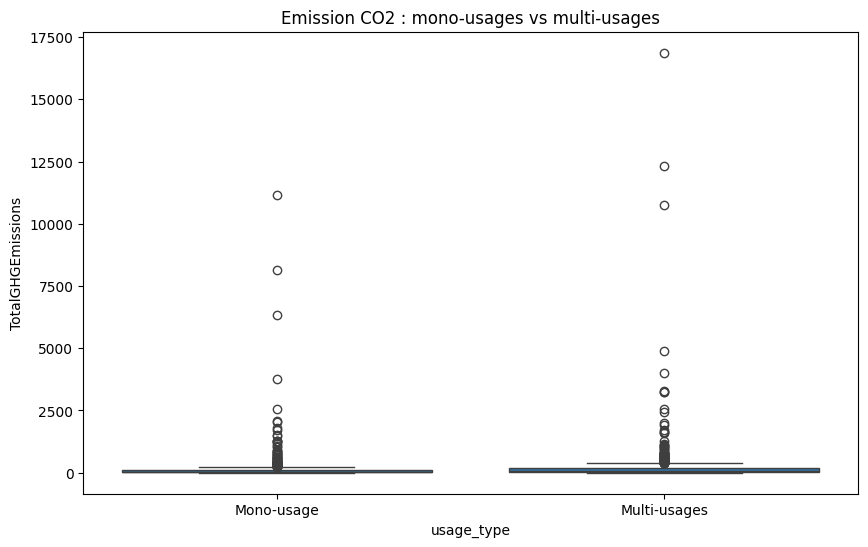

In [36]:
# figure de comparaison mono vs multi usages
plt.figure(figsize=(10, 6))

sns.boxplot( data=building_consumption_NR, x="usage_type", y="TotalGHGEmissions")
plt.title("Emission CO2 : mono-usages vs multi-usages")
plt.xlabel("usage_type")
plt.ylabel("TotalGHGEmissions")
plt.xticks([0, 1], ["Mono-usage", "Multi-usages"])
plt.savefig(FIG_DIR / "analyse_descriptive_NR_mono_multi_emission.png", dpi=300)
plt.show()

`Neighborhood` contient des doublons de casse : on normalise en majuscules avant tout regroupement.

In [37]:
# traitement des doublons dans la colonne 'Neighborhood'
building_consumption_NR['Neighborhood'].value_counts()

Neighborhood
DOWNTOWN                  343
GREATER DUWAMISH          342
MAGNOLIA / QUEEN ANNE     148
LAKE UNION                142
NORTHEAST                 124
EAST                      116
NORTHWEST                  80
BALLARD                    60
NORTH                      56
CENTRAL                    48
SOUTHEAST                  45
DELRIDGE                   41
SOUTHWEST                  40
North                       9
Ballard                     6
Northwest                   5
Delridge                    4
Central                     3
DELRIDGE NEIGHBORHOODS      1
Name: count, dtype: int64

In [38]:
# mettre tout en majuscule afin d'éviter les doublons
building_consumption_NR['Neighborhood'] = (building_consumption_NR['Neighborhood'].str.strip().str.upper())
building_consumption_NR['Neighborhood'].value_counts()

Neighborhood
DOWNTOWN                  343
GREATER DUWAMISH          342
MAGNOLIA / QUEEN ANNE     148
LAKE UNION                142
NORTHEAST                 124
EAST                      116
NORTHWEST                  85
BALLARD                    66
NORTH                      65
CENTRAL                    51
SOUTHEAST                  45
DELRIDGE                   45
SOUTHWEST                  40
DELRIDGE NEIGHBORHOODS      1
Name: count, dtype: int64

### Ce que retient l'analyse exploratoire

- Le périmètre passe de **3 376 à 1 613 bâtiments** après restriction au non-résidentiel et retrait des relevés manquants.
- Les bâtiments **multi-usages** se distinguent nettement des mono-usages sur les émissions.
- `ENERGYSTARScore` est écarté : 25 % de valeurs manquantes, et il est calculé à partir des consommations que l'on cherche à prédire.
- Les libellés de `Neighborhood` et de types d'usage demandent un regroupement avant encodage.

# Modélisation 

### Import des modules 

In [39]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    RandomizedSearchCV
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from xgboost import XGBRegressor
from scipy.stats import uniform, randint

### Feature Engineering

On enrichit le jeu avec des variables dérivées des colonnes existantes : mix énergétique, âge du bâtiment, profil d'usage par surface.

Part de chaque source d'énergie dans la consommation totale (électricité, gaz, autres), après correction d'une valeur d'électricité négative.

In [40]:
# corriger la valeur (1 seule) d'électricité négative à 0
building_consumption_NR['Electricity(kBtu)'] = (building_consumption_NR['Electricity(kBtu)'].clip(lower=0))

# colonnes de types d'énergie
col_Energy = ['Electricity(kBtu)','NaturalGas(kBtu)']

# somme des énérgies
sumEnergy = (building_consumption_NR[col_Energy].fillna(0)).sum(axis=1)

# scale par rapport à l'énergie totale 'SiteEnergyUse(kBtu)'
scaleEnergy = (building_consumption_NR['SiteEnergyUse(kBtu)']/sumEnergy).where(sumEnergy>building_consumption_NR['SiteEnergyUse(kBtu)'], 1.0) 
EnergyScaled = building_consumption_NR[col_Energy].mul(scaleEnergy, axis=0)
building_consumption_NR[col_Energy] = EnergyScaled
building_consumption_NR["OtherEnergy"] = building_consumption_NR['SiteEnergyUse(kBtu)'] - EnergyScaled.sum(axis=1)

# Energy percentage 
building_consumption_NR['ElectricityPercentage'] = building_consumption_NR['Electricity(kBtu)']*100/building_consumption_NR['SiteEnergyUse(kBtu)']
building_consumption_NR['NaturalGasPercentage'] = building_consumption_NR['NaturalGas(kBtu)']*100/building_consumption_NR['SiteEnergyUse(kBtu)']
building_consumption_NR['OtherEnergyPercentage'] = building_consumption_NR['OtherEnergy']*100/building_consumption_NR['SiteEnergyUse(kBtu)']
# building_consumption_NR['OtherEnergyPercentage'] = ((building_consumption_NR['SiteEnergyUse(kBtu)']
#                                                     -building_consumption_NR['NaturalGas(kBtu)']
#                                                     -building_consumption_NR['Electricity(kBtu)'])
#                                                     *100/building_consumption_NR['SiteEnergyUse(kBtu)'])
building_consumption_NR.head()

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type,OtherEnergy,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.0,NaN,NaN,NaN,NaN,7226362.5,249.98,1,0,2003882.5,54.605993,17.663838,27.730169
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,295.86,3,1,0.0,38.660907,61.339093,0.000000
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,49526664.0,1493800.0,Hotel,756493.0,NaN,NaN,NaN,NaN,72587024.0,2089.28,1,0,21566560.0,68.230741,2.057944,29.711316
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2768924.0,1811213.0,Hotel,61320.0,NaN,NaN,NaN,NaN,6794584.0,286.43,1,0,2214447.0,40.751928,26.656717,32.591355
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5368607.0,8803998.0,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,505.01,3,1,1.0,37.880168,62.119825,0.000007


In [41]:
building_consumption_NR.describe()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type,OtherEnergy,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage
count,1613.000000,1613.000000,1613.000000,1.613000e+03,1613.000000,1.613000e+03,1.613000e+03,1.613000e+03,1.613000e+03,818.000000,322.000000,1.613000e+03,1613.000000,1613.000000,1613.000000,1.613000e+03,1613.000000,1613.000000,1.613000e+03
mean,1.202728,4.117793,1961.945443,1.177660e+05,12857.772474,1.049082e+05,5.918112e+06,1.995345e+06,9.900302e+04,35545.252197,13771.647201,8.572254e+06,188.116249,1.855549,0.507750,6.587972e+05,69.463412,27.993358,2.543230e+00
std,2.969730,6.584044,32.479228,2.980259e+05,42401.310897,2.851314e+05,2.110379e+07,9.515669e+06,2.794369e+05,65656.406919,36360.331713,3.069662e+07,763.623218,1.172298,0.500095,7.531176e+06,26.463067,26.506310,1.053783e+01
min,1.000000,1.000000,1900.000000,1.128500e+04,0.000000,3.636000e+03,0.000000e+00,0.000000e+00,5.656000e+03,0.000000,0.000000,2.410550e+04,-0.800000,1.000000,0.000000,-4.656613e-10,0.000000,0.000000,-1.908847e-14
25%,1.000000,1.000000,1930.000000,2.925800e+04,0.000000,2.830400e+04,7.232398e+05,0.000000e+00,2.558000e+04,5098.250000,2477.500000,1.252324e+06,20.460000,1.000000,0.000000,0.000000e+00,48.379461,0.000000,0.000000e+00
50%,1.000000,2.000000,1965.000000,4.892400e+04,0.000000,4.680000e+04,1.619177e+06,5.038750e+05,4.392000e+04,11921.500000,5485.500000,2.590622e+06,49.790000,2.000000,1.000000,3.750000e-01,69.442789,24.401525,1.003517e-05
75%,1.000000,4.000000,1989.000000,1.040990e+05,0.000000,9.447200e+04,4.897760e+06,1.528541e+06,9.212900e+04,30949.750000,11849.000000,6.960904e+06,144.410000,2.000000,1.000000,1.000000e+00,99.945496,49.701695,2.197924e-05
max,111.000000,99.000000,2015.000000,9.320156e+06,512608.000000,9.320156e+06,6.570744e+08,2.979090e+08,9.320156e+06,639931.000000,459748.000000,8.739237e+08,16870.980000,13.000000,1.000000,2.168493e+08,100.000000,100.000000,1.000000e+02


In [42]:
# # vérification des valeurs d'énergie (valeurs négatives)
# mask_neg = building_consumption_NR['Electricity(kBtu)'] < 0
# mask_neg.sum()
# building_consumption_NR[building_consumption_NR['Electricity(kBtu)'] < 0].head()

In [43]:
# building_consumption_NR['Electricity'] = (building_consumption_NR['Electricity(kBtu)']> 0).astype(int)
# building_consumption_NR['NaturalGas'] = (building_consumption_NR['NaturalGas(kBtu)'] > 0).astype(int)
# building_consumption_NR[['Electricity', 'NaturalGas']].value_counts()

Âge du bâtiment en 2016, plus directement interprétable que l'année de construction.

In [44]:
# âge du bâtiment
building_consumption_NR['BuildingAge'] = 2016 - building_consumption_NR['YearBuilt']
building_consumption_NR.head()

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type,OtherEnergy,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.0,NaN,NaN,NaN,NaN,7226362.5,249.98,1,0,2003882.5,54.605993,17.663838,27.730169,89
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,295.86,3,1,0.0,38.660907,61.339093,0.000000,20
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,49526664.0,1493800.0,Hotel,756493.0,NaN,NaN,NaN,NaN,72587024.0,2089.28,1,0,21566560.0,68.230741,2.057944,29.711316,47
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2768924.0,1811213.0,Hotel,61320.0,NaN,NaN,NaN,NaN,6794584.0,286.43,1,0,2214447.0,40.751928,26.656717,32.591355,90
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5368607.0,8803998.0,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,505.01,3,1,1.0,37.880168,62.119825,0.000007,36


### Construction du nouveau dataframe avec un % de surface de tout type de bâtiment multi-usage

In [45]:
# Surface percentage according to the LargestPropertyType, SecondLargestPropertyType, ThirdLargestPropertyType
building_consumption_NR['LargestGFAPercentage'] = building_consumption_NR['LargestPropertyUseTypeGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']
building_consumption_NR['SecondLargestGFAPercentage'] = building_consumption_NR['SecondLargestPropertyUseTypeGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']
building_consumption_NR['ThirdLargestGFAPercentage'] = building_consumption_NR['ThirdLargestPropertyUseTypeGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']

building_consumption_NR['OtherGFAPercentage'] = ((building_consumption_NR['PropertyGFATotal']
                                                    -building_consumption_NR['LargestPropertyUseTypeGFA'].fillna(0)
                                                    -building_consumption_NR['SecondLargestPropertyUseTypeGFA'].fillna(0)
                                                    -building_consumption_NR['ThirdLargestPropertyUseTypeGFA'].fillna(0))
                                                    *100/building_consumption_NR['PropertyGFATotal'])

building_consumption_NR.head()

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type,OtherEnergy,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge,LargestGFAPercentage,SecondLargestGFAPercentage,ThirdLargestGFAPercentage,OtherGFAPercentage
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.0,NaN,NaN,NaN,NaN,7226362.5,249.98,1,0,2003882.5,54.605993,17.663838,27.730169,89,100.000000,0.000000,0.000000,0.000000
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,295.86,3,1,0.0,38.660907,61.339093,0.000000,20,80.991831,14.545314,4.462855,0.000000
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,49526664.0,1493800.0,Hotel,756493.0,NaN,NaN,NaN,NaN,72587024.0,2089.28,1,0,21566560.0,68.230741,2.057944,29.711316,47,79.121963,0.000000,0.000000,20.878037
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2768924.0,1811213.0,Hotel,61320.0,NaN,NaN,NaN,NaN,6794584.0,286.43,1,0,2214447.0,40.751928,26.656717,32.591355,90,100.000000,0.000000,0.000000,0.000000
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5368607.0,8803998.0,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,505.01,3,1,1.0,37.880168,62.119825,0.000007,36,70.306983,38.733910,0.000000,-9.040893


Normalisation des surfaces pour que les trois usages déclarés totalisent 100 %.

In [46]:
# normalisation des surfaces pour que le total soit à 100%
col_GFA = ['LargestPropertyUseTypeGFA','SecondLargestPropertyUseTypeGFA','ThirdLargestPropertyUseTypeGFA']
sumGFA = (building_consumption_NR[col_GFA].fillna(0)).sum(axis=1)

scaleGFA = (building_consumption_NR['PropertyGFATotal']/sumGFA).where(sumGFA>building_consumption_NR['PropertyGFATotal'], 1.0) 
GFAscaled = building_consumption_NR[col_GFA].mul(scaleGFA, axis=0)
building_consumption_NR[col_GFA] = GFAscaled
building_consumption_NR["OtherGFA"] = building_consumption_NR['PropertyGFATotal'] - GFAscaled.sum(axis=1)

# recalcul des % de surfaces
building_consumption_NR['LargestGFAPercentage'] = building_consumption_NR['LargestPropertyUseTypeGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']
building_consumption_NR['SecondLargestGFAPercentage'] = building_consumption_NR['SecondLargestPropertyUseTypeGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']
building_consumption_NR['ThirdLargestGFAPercentage'] = building_consumption_NR['ThirdLargestPropertyUseTypeGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']
building_consumption_NR['OtherGFAPercentage'] = building_consumption_NR['OtherGFA'].fillna(0)*100/building_consumption_NR['PropertyGFATotal']
building_consumption_NR

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type,OtherEnergy,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge,LargestGFAPercentage,SecondLargestGFAPercentage,ThirdLargestGFAPercentage,OtherGFAPercentage,OtherGFA
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3.946027e+06,1.276453e+06,Hotel,88434.000000,NaN,NaN,NaN,NaN,7.226362e+06,249.98,1,0,2.003882e+06,54.605993,17.663838,2.773017e+01,89,100.000000,0.000000,0.000000,0.000000,0.0
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3.242851e+06,5.145082e+06,Hotel,83880.000000,Parking,15064.000000,Restaurant,4622.0,8.387933e+06,295.86,3,1,0.000000e+00,38.660907,61.339093,0.000000e+00,20,80.991831,14.545314,4.462855,0.000000,0.0
2,Hotel,NonResidential,DOWNTOWN,1.0,41,1969,956110,196718,759392,4.952666e+07,1.493800e+06,Hotel,756493.000000,NaN,NaN,NaN,NaN,7.258702e+07,2089.28,1,0,2.156656e+07,68.230741,2.057944,2.971132e+01,47,79.121963,0.000000,0.000000,20.878037,199617.0
3,Hotel,NonResidential,DOWNTOWN,1.0,10,1926,61320,0,61320,2.768924e+06,1.811213e+06,Hotel,61320.000000,NaN,NaN,NaN,NaN,6.794584e+06,286.43,1,0,2.214447e+06,40.751928,26.656717,3.259136e+01,90,100.000000,0.000000,0.000000,0.000000,0.0
4,Hotel,NonResidential,DOWNTOWN,1.0,18,1980,175580,62000,113580,5.368607e+06,8.803998e+06,Hotel,113209.821158,Parking,62370.178842,Swimming Pool,0.0,1.417261e+07,505.01,3,1,1.000000e+00,37.880168,62.119825,7.055865e-06,36,64.477629,35.522371,0.000000,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,Office,Nonresidential COS,GREATER DUWAMISH,1.0,1,1990,12294,0,12294,5.242707e+05,3.254749e+05,Office,12294.000000,NaN,NaN,NaN,NaN,8.497457e+05,20.94,1,0,0.000000e+00,61.697370,38.302630,0.000000e+00,26,100.000000,0.000000,0.000000,0.000000,0.0
3372,Other,Nonresidential COS,DOWNTOWN,1.0,1,2004,16000,0,16000,3.965461e+05,5.537300e+05,Other - Recreation,16000.000000,NaN,NaN,NaN,NaN,9.502762e+05,32.17,1,0,1.550000e-01,41.729558,58.270426,1.631105e-05,12,100.000000,0.000000,0.000000,0.000000,0.0
3373,Other,Nonresidential COS,MAGNOLIA / QUEEN ANNE,1.0,1,1974,13157,0,13157,1.792159e+06,3.973739e+06,Other - Recreation,7583.000000,Fitness Center/Health Club/Gym,5574.000000,Swimming Pool,0.0,5.765898e+06,223.54,3,1,1.790000e-01,31.082041,68.917956,3.104460e-06,42,57.634719,42.365281,0.000000,0.000000,0.0
3374,Mixed Use Property,Nonresidential COS,GREATER DUWAMISH,1.0,1,1989,14101,0,14101,3.488702e+05,3.706010e+05,Other - Recreation,6601.000000,Fitness Center/Health Club/Gym,6501.000000,Pre-school/Daycare,484.0,7.194712e+05,22.11,5,1,1.050000e-02,48.489805,51.510194,1.459405e-06,27,46.812283,46.103113,3.432381,3.652223,515.0


Bascule en format large : une colonne de part de surface par type d'usage (`PropertyUseType_*`), puis jointure au jeu principal.

In [47]:
col_type = ['LargestPropertyUseType','SecondLargestPropertyUseType','ThirdLargestPropertyUseType']
col_GFA_Percentage = ['LargestGFAPercentage','SecondLargestGFAPercentage','ThirdLargestGFAPercentage']
long_parts = []

for t_col, g_col in zip(col_type, col_GFA_Percentage):
    temp = pd.DataFrame({
        'building_id': building_consumption_NR.index,
        'Property_use_type': building_consumption_NR[t_col],
        'GFA%': building_consumption_NR[g_col]
    }, index=building_consumption_NR.index)
    long_parts.append(temp)

long_df = pd.concat(long_parts)

# Remplacer NaN
long_df['Property_use_type'] = long_df['Property_use_type'].fillna("Other")
long_df['GFA%'] = long_df['GFA%'].fillna(0)
long_df

# agréger par bâtiment et par catégorie
#GFA_Percentage_grouped = (long_df.groupby([long_df.index, 'Property_use_type'])['GFA%'].sum())
#GFA_Percentage_grouped

df_pivot = long_df.pivot_table(index='building_id', columns='Property_use_type',values='GFA%', aggfunc="sum", fill_value=0)
df_pivot = df_pivot.add_prefix("PropertyUseType_")
#df_pivot.columns = ("PropertyUseType_" + df_pivot.columns.str.replace(" ", "", regex=False).str.replace("/", "", regex=False))
df_pivot.head(20)

Property_use_type,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
building_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,100.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,80.991831,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.545314,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,4.462855,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,79.121963,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,100.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,64.477629,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35.522371,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0

In [48]:
# vérifier si les index sont identiques
print(df_pivot.index.equals(building_consumption_NR.index))

True


In [49]:
building_consumption_NR = building_consumption_NR.merge(df_pivot,left_index=True,right_index=True,how="left")
building_consumption_NR.head(20)

,PrimaryPropertyType,BuildingType,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),Electricity(kBtu),NaturalGas(kBtu),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,nb_property_use_types,usage_type,OtherEnergy,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge,LargestGFAPercentage,SecondLargestGFAPercentage,ThirdLargestGFAPercentage,OtherGFAPercentage,OtherGFA,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
0,Hotel,NonResidential,DOWNTOWN,1.0,12,1927,88434,0,88434,3946027.0,1276453.0,Hotel,88434.000000,NaN,NaN,NaN,NaN,7226362.5,249.98,1,0,2003882.5,54.605993,17.663838,27.730169,89,100.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,100.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Hotel,NonResidential,DOWNTOWN,1.0,11,1996,103566,15064,88502,3242851.0,5145082.0,Hotel,83880.000000,Parking,15064.000000,Restaurant,4622.000000,8387933.0,295.86,3,1,0.0,38.660907,61.339093,0.000000,20,80.991831,14.545314,4.462855,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,80.991831,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.545314,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,4.462855,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Hotel,NonResidential,DO

In [50]:
building_consumption_NR.shape

(1613, 94)

Les cellules suivantes conservent des pistes explorées puis écartées : ratios de surface bâtie/parking, et regroupement de `PrimaryPropertyType`.

In [51]:
# # % des surfaces de bâtiments par rapport aux surfaces globales
# building_consumption_NR['PropertyGFABuildingRatio'] = (building_consumption_NR['PropertyGFABuilding(s)']*100/building_consumption_NR['PropertyGFATotal']).round(2)
# building_consumption_NR['PropertyGFAParkingRatio'] = 100 - building_consumption_NR['PropertyGFABuildingRatio']
# building_consumption_NR.head()

In [52]:
# # mapping sur la colonne 'PrimaryPropertyType'
# building_consumption_NR['PrimaryPropertyType'].value_counts()

In [53]:
# mapping_PropertyType = {
#     # Offices
#     'Small- and Mid-Sized Office': 'Office',
#     'Large Office': 'Office',
#     'Office': 'Office',
#     #'Medical Office': 'Office',

#     # Education
#     'K-12 School': 'Education',
#     'University': 'Education',

#     # Retail / Commerce
#     'Retail Store': 'Commercial',
#     'Supermarket / Grocery Store': 'Commercial',
#     'Self-Storage Facility': 'Commercial',


#     # Warehouse / Logistics
#     'Warehouse': 'Warehouse',
#     'Refrigerated Warehouse': 'Warehouse',
#     'Distribution Center': 'Warehouse',

#     # Hospitality
#     'Hotel': 'Hospitality',
    
#     # Restaurant
#     'Restaurant': 'Restaurant',
    
#     # Healthcare
#     'Hospital': 'Healthcare',
#     'Medical Office' : 'Healthcare',
#     'Senior Care Community ' : 'Healthcare',

#     # Religious
#     'Worship Facility' : 'Religious',

#     # Laboratory
#     'Laboratory ': 'Laboratory',
    
#     # MixedUse
#     'Mixed Use Property' : 'MixedUse',
#     'Other' : 'MixedUse'
# }


In [54]:
# building_consumption_NR['PrimaryPropertyType_grouped'] = (building_consumption_NR['PrimaryPropertyType'].map(mapping_PropertyType).fillna('Other'))
# building_consumption_NR['PrimaryPropertyType_grouped'].value_counts()

In [55]:
# # suppression de la catégorie other fortement résidentiel 
# building_consumption_NR = building_consumption_NR[building_consumption_NR['PrimaryPropertyType_grouped'] != 'Other']

# pd.set_option('display.max_columns', None)
# building_consumption_NR.head()

### Préparation des features pour la modélisation

Sélection finale des variables, traitement des valeurs extrêmes, contrôle des corrélations, puis encodage des variables catégorielles.

In [56]:
# suppression des colonnes peu pertinentes pour la modélisation
# features_modele = ['Neighborhood',
#                    'NumberofBuildings',
#                    'NumberofFloors',
#                    'PropertyGFATotal',
#                    'PropertyGFABuildingRatio',
#                    'nb_property_use_types',
#                    'usage_type',
#                    'Electricity',
#                    'NaturalGas',
#                    'BuildingAge',
#                    'PrimaryPropertyType_grouped',
#                    'SiteEnergyUseWN(kBtu)']

features_drop = ['PrimaryPropertyType',
                 'BuildingType',
                 'PropertyGFAParking',
                 'PropertyGFABuilding(s)',
                 'Electricity(kBtu)',
                 'NaturalGas(kBtu)',
                 'OtherEnergy',
                 'LargestPropertyUseType',
                 'LargestPropertyUseTypeGFA',
                 'SecondLargestPropertyUseType',
                 'SecondLargestPropertyUseTypeGFA',
                 'ThirdLargestPropertyUseType',
                 'ThirdLargestPropertyUseTypeGFA',
                 'SiteEnergyUse(kBtu)',
                 'LargestGFAPercentage',
                 'SecondLargestGFAPercentage',
                 'ThirdLargestGFAPercentage',
                 'OtherGFAPercentage',
                 'OtherGFA']


building_consumption_NR_reduced = building_consumption_NR.drop(columns=features_drop)



#target_model = []

#building_consumption_NR_reduced = building_consumption_NR[features_modele]
building_consumption_NR_reduced.head()

,Neighborhood,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,TotalGHGEmissions,nb_property_use_types,usage_type,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
0,DOWNTOWN,1.0,12,1927,88434,249.98,1,0,54.605993,17.663838,27.730169,89,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,DOWNTOWN,1.0,11,1996,103566,295.86,3,1,38.660907,61.339093,0.000000,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,80.991831,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.545314,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.462855,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DOWNTOWN,1.0,41,1969,956110,2089.28,1,0,68.230741,2.057944,29.711316,47,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,79.121963,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,DOWNTOWN,1.0,10,1926,61320,286.43,1,0,40.751928,26.656717,32.591355,90,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,DOWNTOWN,1.0,18,1980,175580,505.01,3,1,37.880168,62.119825,0.000007,36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64.477629,0.0,0.0,0.0,0.0,0

In [57]:
#building_consumption_NR_reduced.fillna(0, inplace=True)
building_consumption_NR_reduced.describe()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,TotalGHGEmissions,nb_property_use_types,usage_type,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
count,1613.000000,1613.000000,1613.000000,1.613000e+03,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1.613000e+03,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.000000,1613.0,1613.000000,1613.000000,1613.000000,1613.000000
mean,1.202728,4.117793,1961.945443,1.177660e+05,188.116249,1.855549,0.507750,69.463412,27.993358,2.543230e+00,54.054557,0.147053,0.311486,0.267137,0.021734,1.430466,0.001110,0.080983,0.248211,3.089478,0.021019,0.003163,0.225058,0.061996,0.551903,0.034296,0.103477,0.530057,4.142105,7.696627,0.703802,0.152338,0.120350,0.501446,2.065843,0.098814,0.252077,11.139489,25.642088,5.736140,0.134555,1.158220,0.294902,0.170041,0.166545,1.563261,0.068726,0.443162,0.002966,0.108834,0.243658,5.073752,0.198028,0.076721,0.056606,0.133016,0.185989,0.715986,0.418192,1.218944,0.061996,1.078233,6.437925,1.702364,1.065158,0.061996,0.509617,0.310963,2.322408,0.0,0.247985,0

Contrôle des valeurs infinies ou aberrantes produites par les divisions de pourcentage.

In [58]:
# vérification des erreurs inf dans le calcul de % d'énergie
num = building_consumption_NR_reduced.select_dtypes(include=[np.number])

bad = {}
for c in num.columns:
    bad[c] = {
        "nan": int(num[c].isna().sum()),
        "inf": int(np.isinf(num[c]).sum()),
    }
{k:v for k,v in bad.items() if v["nan"]>0 or v["inf"]>0}

{}

In [59]:
# building_consumption_NR_clean = building_consumption_NR_reduced.copy()

# #num_cols = building_consumption_NR_clean.select_dtypes(include=['int64', 'float64']).columns

# num_cols = ['NumberofFloors',
#             'SiteEnergyUseWN(kBtu)']

# #num_cols = 'NumberofFloors'
# limits = []

# for col in num_cols:
#     Q1, Q3 = np.quantile(building_consumption_NR_clean[col].dropna(), [0.25, 0.75])
#     IQR = Q3 - Q1
    
#     limite_basse = Q1 - 1.5 * IQR
#     limite_haute = Q3 + 1.5 * IQR
    
#     if limite_basse<0:
#         limite_basse = 0
        
#     building_consumption_NR_clean = building_consumption_NR_clean[(building_consumption_NR_clean[col] >= limite_basse) & (building_consumption_NR_clean[col] <= limite_haute)]
    
#     limits.append({
#         'feature': col,
#         'Q1': Q1,
#         'Q3': Q3,
#         'limite_basse': limite_basse,
#         'limite_haute': limite_haute
#          })
    
# building_consumption_NR_clean.reset_index(drop=True)
# print("Avant :", building_consumption_NR_reduced.shape)
# print("Après :", building_consumption_NR_clean.shape)

# limits_df = pd.DataFrame(limits)
# limits_df

Retrait des valeurs extrêmes de `NumberofFloors` par la règle IQR : 1 613 → 1 480 bâtiments.

In [60]:
building_consumption_NR_clean = building_consumption_NR_reduced.copy()

#num_cols = building_consumption_NR_clean.select_dtypes(include=['int64', 'float64']).columns


num_cols = 'NumberofFloors'
limits = []

Q1, Q3 = np.quantile(building_consumption_NR_clean[num_cols].dropna(), [0.25, 0.75])
IQR = Q3 - Q1
    
limite_basse = Q1 - 1.5 * IQR
limite_haute = Q3 + 1.5 * IQR

if limite_basse<0: 
    limite_basse = 0
 
building_consumption_NR_clean = building_consumption_NR_clean[(building_consumption_NR_clean[num_cols] >= limite_basse) & (building_consumption_NR_clean[num_cols] <= limite_haute)]
     
building_consumption_NR_clean.reset_index(drop=True)
print("Avant :", building_consumption_NR_reduced.shape)
print("Après :", building_consumption_NR_clean.shape)


Avant : (1613, 75)
Après : (1480, 75)


In [61]:
building_consumption_NR_clean.describe()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFATotal,TotalGHGEmissions,nb_property_use_types,usage_type,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,BuildingAge,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
count,1480.000000,1480.000000,1480.000000,1.480000e+03,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1.480000e+03,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.0,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.0,1480.000000,1480.000000,1480.000000,1480.000000
mean,1.212162,2.656757,1961.200000,8.973342e+04,154.793486,1.803378,0.487162,68.745875,29.443685,1.810440e+00,54.800000,0.160268,0.339478,0.284443,0.019695,1.559015,0.000058,0.021095,0.234652,3.367113,0.022908,0.003447,0.221960,0.067568,0.592303,0.037378,0.105157,0.456893,2.812287,8.388283,0.750876,0.106613,0.131166,0.546508,2.040672,0.107694,0.274730,12.140537,23.572911,5.958346,0.145028,1.262303,0.321403,0.185321,0.181511,1.698111,0.035520,0.482986,0.0,0.118614,0.265555,4.451956,0.215824,0.080445,0.061693,0.143791,0.202703,0.780328,0.455772,1.230411,0.067568,1.140436,6.899672,1.855347,1.048813,0.067568,0.555414,0.328441,2.517082,0.0,0.202703,0.037415,0.

Distribution de la cible : fortement asymétrique, ce qui motivera une transformation `log1p` pour le Gradient Boosting.

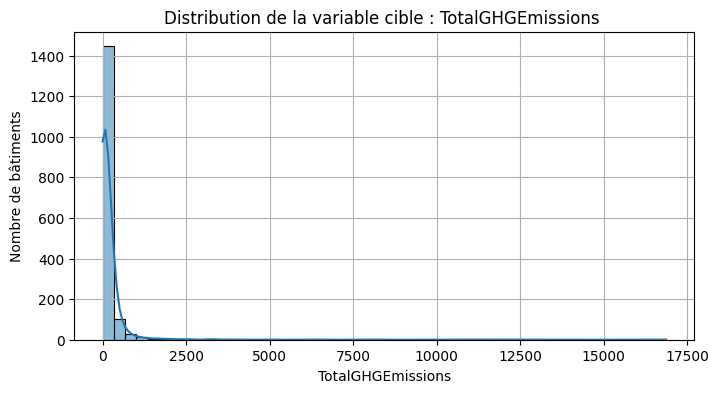

In [62]:
# tracé de la distribution de la cible
target_model = 'TotalGHGEmissions'
plt.figure(figsize=(8, 4))
sns.histplot(building_consumption_NR_reduced[target_model], bins=50, kde=True)
plt.title("Distribution de la variable cible : TotalGHGEmissions ")


plt.xlabel(target_model)
plt.ylabel("Nombre de bâtiments")
plt.grid(True)
plt.savefig(FIG_DIR / "distribution_emission.png", dpi=300)
plt.show()


Liste des variables numériques, parts de surface par usage incluses.

In [63]:
PropertyUseType_cols = [col for col in building_consumption_NR_clean.columns if col.startswith("PropertyUseType_")]

num_features = ['NumberofFloors',
                'NumberofBuildings',
                'PropertyGFATotal',
                'nb_property_use_types',
                'BuildingAge',
                'ElectricityPercentage',
                'NaturalGasPercentage',
                'OtherEnergyPercentage']

num_features += PropertyUseType_cols
building_consumption_NR_clean[num_features]

,NumberofFloors,NumberofBuildings,PropertyGFATotal,nb_property_use_types,BuildingAge,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
5,2,1.0,97288,1,17,60.988402,39.011598,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,91.306225,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,8,1.0,102761,1,90,57.741808,6.115925,3.614227e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,100.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16,6,1.0,103911,3,86,44.733737,9.141661,4.612460e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.230769,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.769231,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18,5,1.0,57452,5,109,49.497097,27.150514,2.335239e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.955023,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,26.987746,0.0,0.0,0.0,0.0,28.618673,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22,2,1.0,56228,1,55,60.861844,39.138124,3.247853e-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0

In [64]:
building_consumption_NR_clean[num_features].describe()

,NumberofFloors,NumberofBuildings,PropertyGFATotal,nb_property_use_types,BuildingAge,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
count,1480.000000,1480.000000,1.480000e+03,1480.000000,1480.000000,1480.000000,1480.000000,1.480000e+03,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.0,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.0,1480.000000,1480.000000,1480.000000,1480.000000
mean,2.656757,1.212162,8.973342e+04,1.803378,54.800000,68.745875,29.443685,1.810440e+00,0.160268,0.339478,0.284443,0.019695,1.559015,0.000058,0.021095,0.234652,3.367113,0.022908,0.003447,0.221960,0.067568,0.592303,0.037378,0.105157,0.456893,2.812287,8.388283,0.750876,0.106613,0.131166,0.546508,2.040672,0.107694,0.274730,12.140537,23.572911,5.958346,0.145028,1.262303,0.321403,0.185321,0.181511,1.698111,0.035520,0.482986,0.0,0.118614,0.265555,4.451956,0.215824,0.080445,0.061693,0.143791,0.202703,0.780328,0.455772,1.230411,0.067568,1.140436,6.899672,1.855347,1.048813,0.067568,0.555414,0.328441,2.517082,0.0,0.202703,0.037415,0.067568,4.540491
std,1.730221,3.093252,2.724477e+05,1.135744,32.454043,26.613573,26.648084,9.320555e+00,3.74

Matrice de corrélation de Pearson, pour éliminer les variables redondantes.

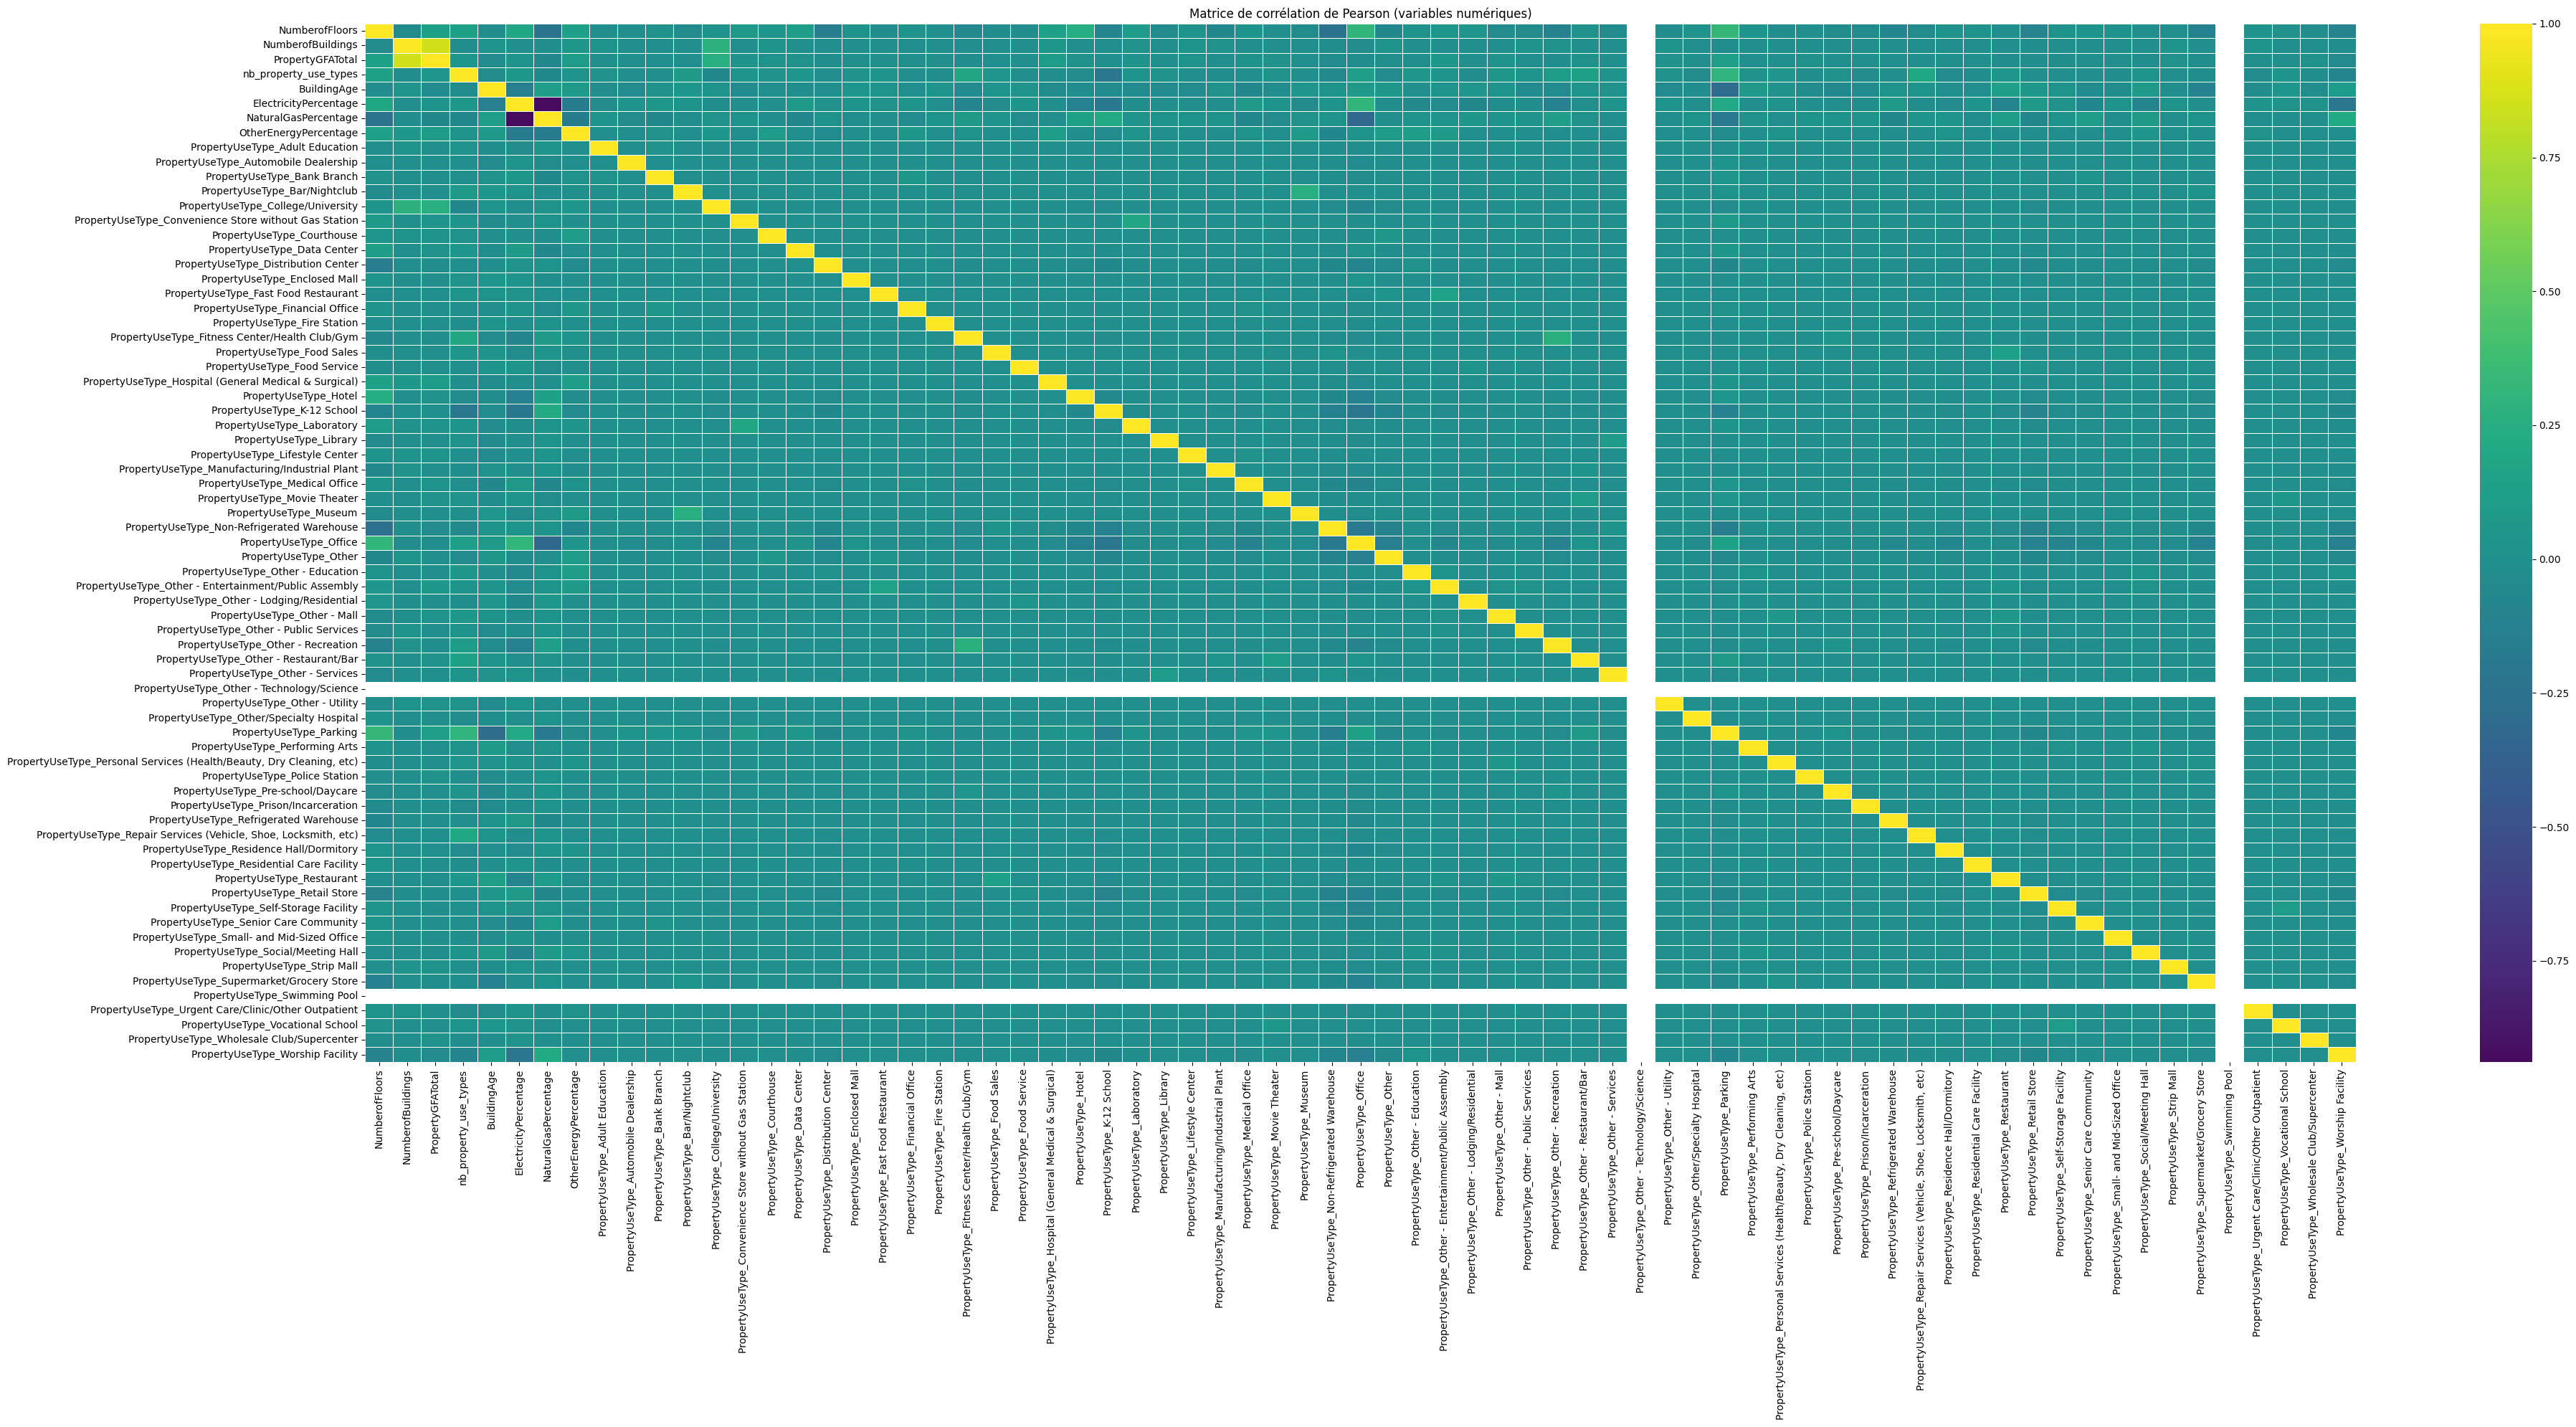

In [65]:
# matrice de corrélation de Pearson, à ne pas garder 'Neighborhood', 'usage_type', 'EnergySource', 'PrimaryPropertyType_grouped'
# num_features = ['NumberofFloors',
#                 'NumberofBuildings',
#                 'PropertyGFATotal',
#                 'PropertyGFABuildingRatio',
#                 'nb_property_use_types',
#                 'BuildingAge']

corr_matrix = building_consumption_NR_clean[num_features].corr(method='pearson')

# heatmap de la matrice de corrélation
plt.figure(figsize=(40,20))
sns.heatmap(corr_matrix, cmap="viridis", center=0, linewidths=0.5)

plt.title("Matrice de corrélation de Pearson (variables numériques)")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_emission.png", dpi=300)
plt.show()

In [66]:
# véhification des fortes corrélations entre colonnes numériques
# forte corrélation entre 'NumberofBuildings' et 'PropertyGFATotal' ==> suppression de 'NumberofBuildings'
corr_matrix[(corr_matrix > 0.7) ]
#corr_matrix[(corr_matrix > 0.7) | (corr_matrix ==0)]

,NumberofFloors,NumberofBuildings,PropertyGFATotal,nb_property_use_types,BuildingAge,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Technology/Science,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility
NumberofFloors,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NumberofBuildings,NaN,1.000000,0.852231,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PropertyGFATotal,NaN,0.852231,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nb_property_use_types,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BuildingAge,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

`NumberofBuildings` est retiré : trop corrélé à `PropertyGFATotal`.

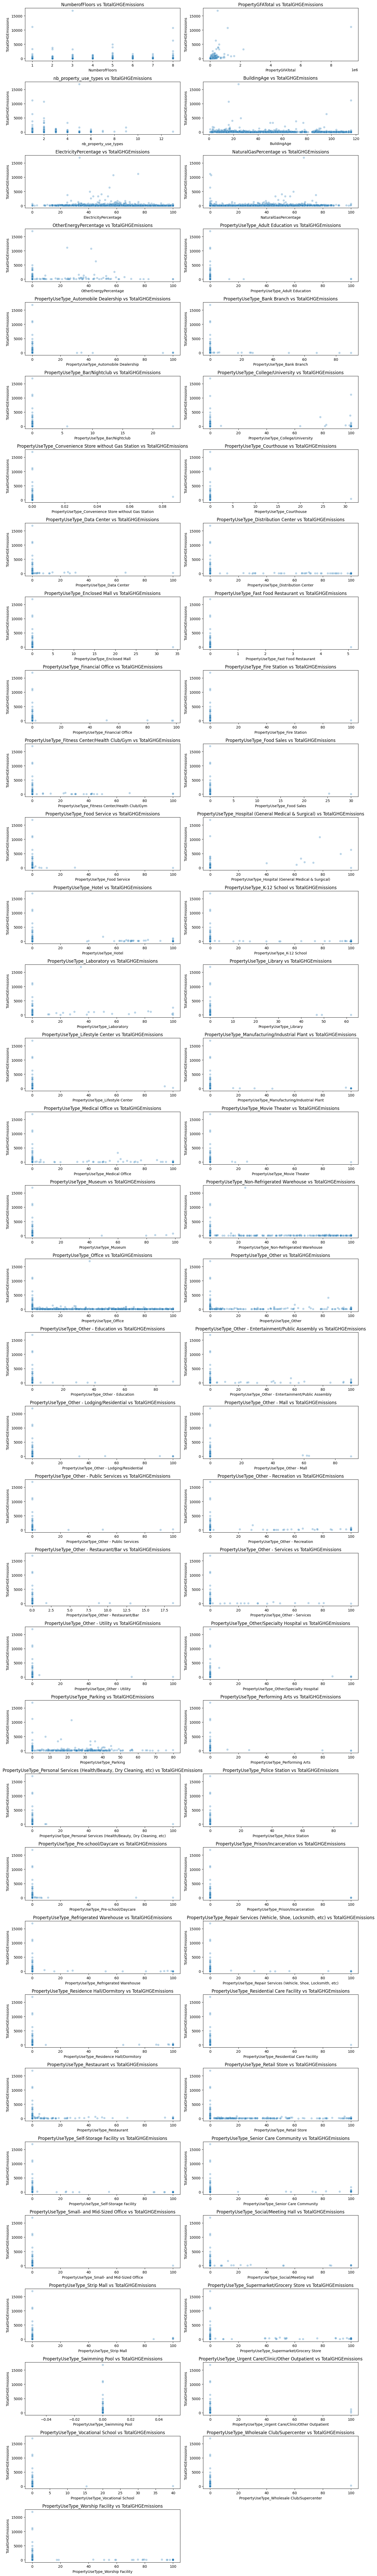

In [67]:
# différents graphiques selon la nature des features

# suppression des features après calcul de la matrice de corrélation
num_features_to_remove = ['NumberofBuildings', 'PropertyUseType_Other - Technology/Science']
num_features = [col for col in num_features if col not in num_features_to_remove]

#num_features = [col for col in num_features if col != ('NumberofBuildings'|'PropertyUseType_Other - Technology/Science')]

cat_features = ['Neighborhood',
                'usage_type']

# num_features = ['NumberofFloors',
#                 'PropertyGFATotal',
#                 'PropertyGFABuildingRatio',
#                 'nb_property_use_types',
#                 'BuildingAge']

# cat_features = ['Neighborhood',
#                 'usage_type',
#                 'Electricity',
#                 'NaturalGas',
#                 'PrimaryPropertyType_grouped']

target = 'TotalGHGEmissions'

plt.figure(figsize=(14, 100))

for i, col in enumerate(num_features, 1):
    plt.subplot(35, 2, i)
    sns.scatterplot(data=building_consumption_NR_clean,x=col,y=target,alpha=0.3)
    plt.title(f"{col} vs {target}")

plt.tight_layout()
plt.show()

In [68]:
len(num_features)

69

In [69]:
## paireplot
#sns.pairplot(building_consumption_NR_clean[num_features + [target]], diag_kind='kde')
#plt.show()

Boxplots des variables catégorielles face à la cible, avec puis sans les valeurs extrêmes.

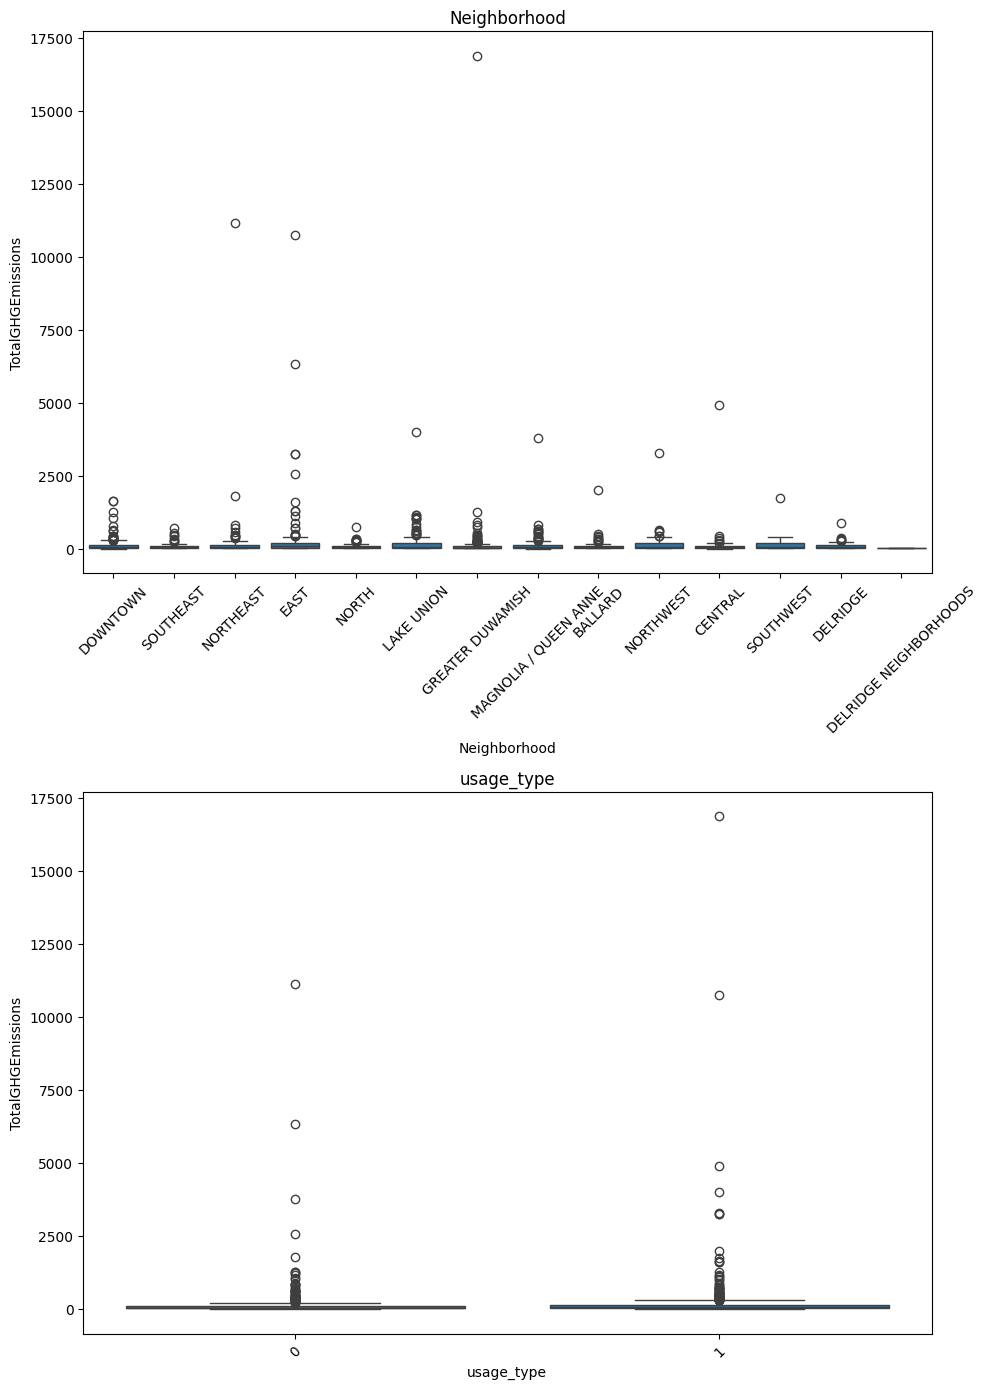

In [70]:
plt.figure(figsize=(10, 14))

for i, col in enumerate(cat_features, 1):
    plt.subplot(len(cat_features), 1, i)
    sns.boxplot(data=building_consumption_NR_clean, x=col, y=target)
    plt.xticks(rotation=45)
    plt.title(col)

plt.tight_layout()
plt.show()

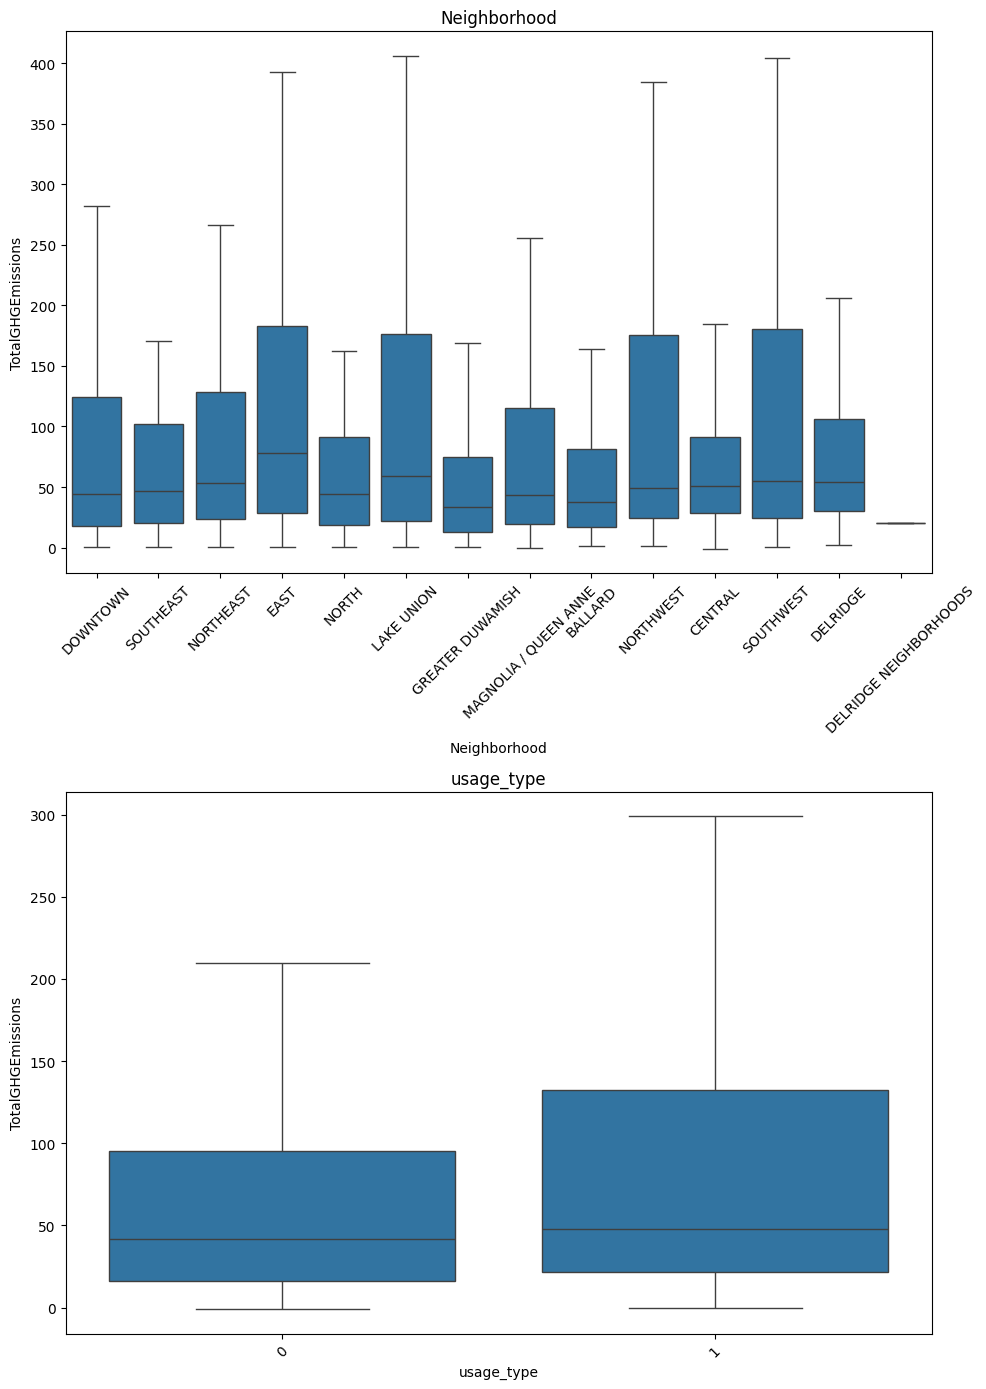

In [71]:
plt.figure(figsize=(10, 14))

for i, col in enumerate(cat_features, 1):
    plt.subplot(len(cat_features), 1, i)
    sns.boxplot(data=building_consumption_NR_clean, x=col, y=target,showfliers=False)
    plt.xticks(rotation=45)
    plt.title(col)

plt.tight_layout()
plt.show()


Séparation en `X` (variables explicatives) et `y` (cible).

In [72]:
# Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target)
y = building_consumption_NR_clean[target]
X = building_consumption_NR_clean[num_features+cat_features]
X.reset_index(inplace=True,drop=True)
X

,NumberofFloors,PropertyGFATotal,nb_property_use_types,BuildingAge,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility,Neighborhood,usage_type
0,2,97288,1,17,60.988402,39.011598,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,91.306225,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DOWNTOWN,0
1,8,102761,1,90,57.741808,6.115925,3.614227e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,100.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DOWNTOWN,0
2,6,103911,3,86,44.733737,9.141661,4.612460e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.230769,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.769231,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DOWNTOWN,1
3,5,57452,5,109,49.497097,27.150514,2.335239e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.955023,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,26.987746,0.0,0.0,0.0,0.0,28.618673,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DOWNTOWN,1
4,2,56228,1,55,60.861844,39.138124,3.247853e-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0000

In [73]:
X['Neighborhood'] = (X['Neighborhood'].str.upper().str.strip())
X['Neighborhood'].value_counts()

C:\Users\faiza\AppData\Local\Temp\ipykernel_10764\555093661.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Neighborhood'] = (X['Neighborhood'].str.upper().str.strip())


Neighborhood
GREATER DUWAMISH          339
DOWNTOWN                  234
MAGNOLIA / QUEEN ANNE     146
LAKE UNION                135
NORTHEAST                 121
EAST                      107
NORTHWEST                  85
BALLARD                    66
NORTH                      65
CENTRAL                    51
SOUTHEAST                  45
DELRIDGE                   45
SOUTHWEST                  40
DELRIDGE NEIGHBORHOODS      1
Name: count, dtype: int64

Regroupement des quartiers en zones géographiques, pour limiter la cardinalité avant encodage.

In [74]:
# mapping sur 'Neighborhood' afin de faciliter l'encodage
neighborhood_grouped = { 'BALLARD': 'North',
                         'NORTH': 'North',
                         'NORTHWEST': 'North',
                         'NORTHEAST': 'North',
                        
                         'GREATER DUWAMISH': 'South',
                         'DELRIDGE': 'South',
                         'DELRIDGE NEIGHBORHOODS': 'South',
                         'SOUTHEAST': 'South',
                         'SOUTHWEST': 'South',

                         'DOWNTOWN': 'Central',
                         'CENTRAL': 'Central',
                         'LAKE UNION': 'Central',
                        
                         'EAST': 'East',
                        
                         'MAGNOLIA / QUEEN ANNE': 'West',
                         'MAGNOLIA / QUEENANNE': 'West'}

X = X.copy()
X['Neighborhood_grouped'] = (X['Neighborhood'].map(neighborhood_grouped).fillna('Other'))
X['Neighborhood_grouped'].value_counts()

Neighborhood_grouped
South      470
Central    420
North      337
West       146
East       107
Name: count, dtype: int64

In [75]:
X['Neighborhood_grouped'].isna().sum()

np.int64(0)

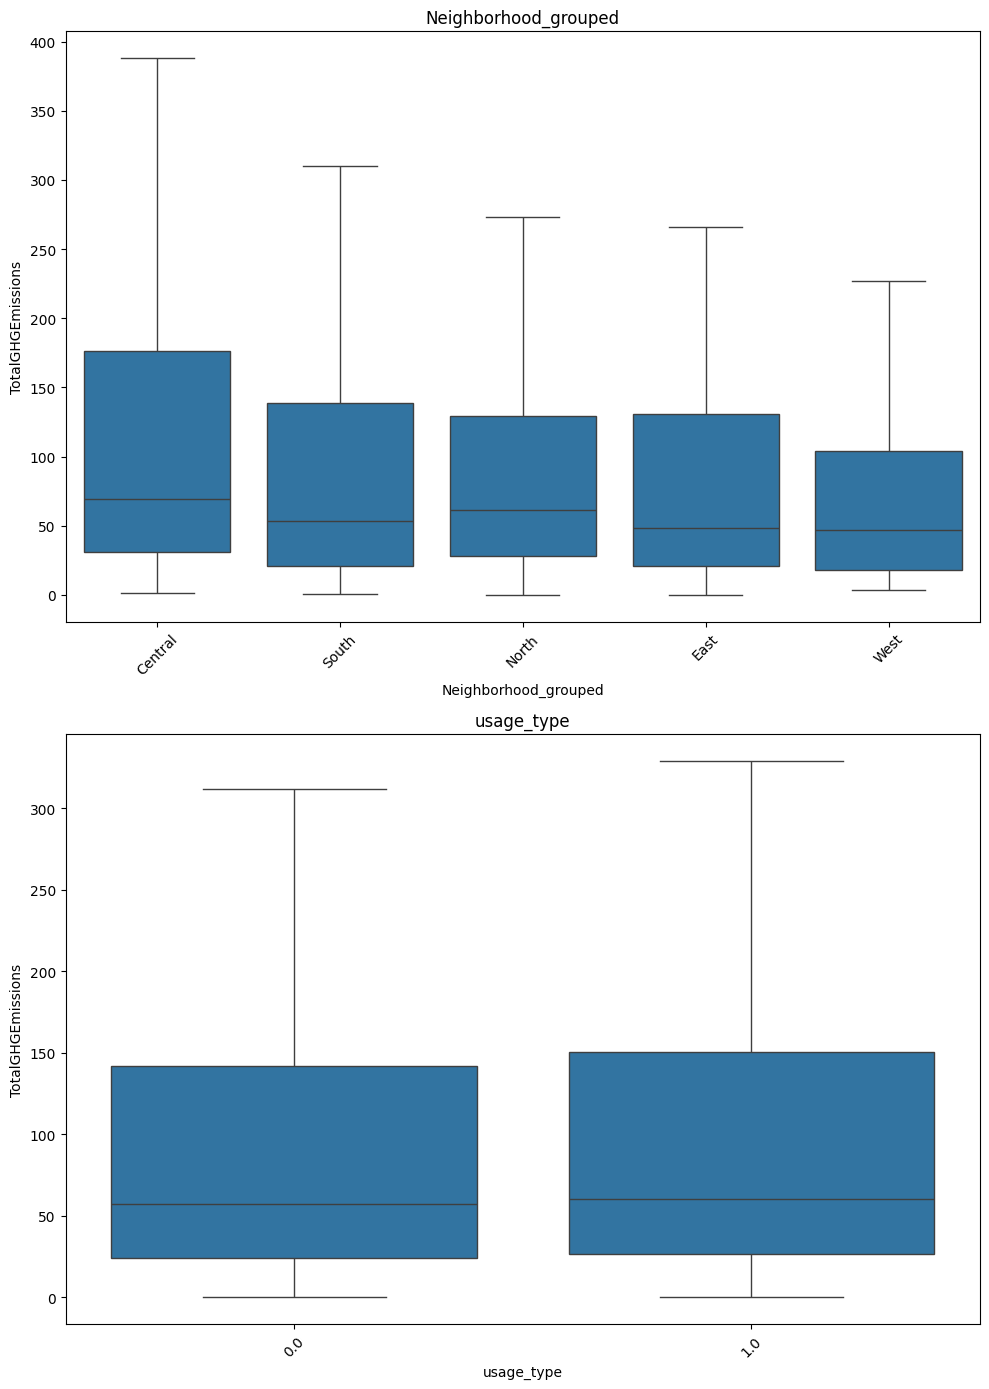

In [76]:
cat_features = ['Neighborhood_grouped',
                'usage_type']
plt.figure(figsize=(10, 14))

for i, col in enumerate(cat_features, 1):
    plt.subplot(len(cat_features), 1, i)
    sns.boxplot(data=X, x=col, y=y, showfliers=False)
    plt.xticks(rotation=45)
    plt.title(col)

plt.tight_layout()
plt.savefig(FIG_DIR / "cat_features_conso_boxplot_emission.png", dpi=300)
plt.show()

Encodage one-hot des variables catégorielles restantes.

In [77]:
# Encodage de 'Neighborhood_grouped'
from sklearn import preprocessing
enc_Neighborhood = preprocessing.OneHotEncoder()
labels_Neighborhood = enc_Neighborhood.fit_transform(X.Neighborhood_grouped.values.reshape(-1, 1)).toarray()
labels_Neighborhood.shape

labels_Neighborhood_df = pd.DataFrame(labels_Neighborhood,columns=enc_Neighborhood.get_feature_names_out(['Neighborhood_grouped']),index=X.index)

labels_Neighborhood_df

,Neighborhood_grouped_Central,Neighborhood_grouped_East,Neighborhood_grouped_North,Neighborhood_grouped_South,Neighborhood_grouped_West
0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...
1475,0.0,0.0,0.0,1.0,0.0
1476,1.0,0.0,0.0,0.0,0.0
1477,0.0,0.0,0.0,0.0,1.0
1478,0.0,0.0,0.0,1.0,0.0


In [78]:
enc_Neighborhood.categories_

[array(['Central', 'East', 'North', 'South', 'West'], dtype=object)]

In [79]:
# # Encodage de 'PrimaryPropertyType_grouped'
# from sklearn import preprocessing
# enc_PrimaryPropertyType = preprocessing.OneHotEncoder()
# labels_PrimaryPropertyType = enc_PrimaryPropertyType.fit_transform(X.PrimaryPropertyType_grouped.values.reshape(-1, 1)).toarray()
# labels_PrimaryPropertyType.shape

# labels_PrimaryPropertyType_df = pd.DataFrame(labels_PrimaryPropertyType,columns=enc_PrimaryPropertyType.get_feature_names_out(['PrimaryPropertyType_grouped']),index=X.index)

# labels_PrimaryPropertyType_df

In [80]:
#enc_PrimaryPropertyType.categories_

In [81]:
#### Encodage de 'EnergySource'
#from sklearn import preprocessing
#enc_EnergySource = preprocessing.OneHotEncoder()
#labels_EnergySource = enc_EnergySource.fit_transform(X.EnergySource.values.reshape(-1, 1)).toarray()
#labels_EnergySource.shape

#labels_EnergySource_df = pd.DataFrame(labels_EnergySource,columns=enc_EnergySource.get_feature_names_out(['EnergySource']),index=X.index)

#labels_EnergySource_df.columns = ['Electricity','NaturalGas','Both']
#labels_EnergySource_df

In [82]:
#enc_EnergySource.categories_

In [83]:
# Encodage de 'usage_type'
from sklearn import preprocessing
enc_usage_type = preprocessing.OneHotEncoder()
labels_usage_type = enc_usage_type.fit_transform(X.usage_type.values.reshape(-1, 1)).toarray()
labels_usage_type.shape

labels_usage_type_df = pd.DataFrame(labels_usage_type,columns=enc_usage_type.get_feature_names_out(['usage_type']),index=X.index)

labels_usage_type_df.columns = ['mono_usage','multi_usages']
labels_usage_type_df

,mono_usage,multi_usages
0,1.0,0.0
1,1.0,0.0
2,0.0,1.0
3,0.0,1.0
4,1.0,0.0
...,...,...
1475,1.0,0.0
1476,1.0,0.0
1477,0.0,1.0
1478,0.0,1.0


In [84]:
enc_usage_type.categories_

[array([0, 1])]

Reconstruction de `X` : les colonnes catégorielles sont remplacées par leur encodage.

In [85]:
# suppression des colonnes catégorielles et remplacer par le resultat de l'encodage de chacune de ces colonnes
cols_to_drop = ['Neighborhood_grouped',
                'Neighborhood',
                'usage_type']
X_encoded = pd.concat([X.drop(columns=cols_to_drop), labels_Neighborhood_df, labels_usage_type_df], axis=1)
X_encoded

,NumberofFloors,PropertyGFATotal,nb_property_use_types,BuildingAge,ElectricityPercentage,NaturalGasPercentage,OtherEnergyPercentage,PropertyUseType_Adult Education,PropertyUseType_Automobile Dealership,PropertyUseType_Bank Branch,PropertyUseType_Bar/Nightclub,PropertyUseType_College/University,PropertyUseType_Convenience Store without Gas Station,PropertyUseType_Courthouse,PropertyUseType_Data Center,PropertyUseType_Distribution Center,PropertyUseType_Enclosed Mall,PropertyUseType_Fast Food Restaurant,PropertyUseType_Financial Office,PropertyUseType_Fire Station,PropertyUseType_Fitness Center/Health Club/Gym,PropertyUseType_Food Sales,PropertyUseType_Food Service,PropertyUseType_Hospital (General Medical & Surgical),PropertyUseType_Hotel,PropertyUseType_K-12 School,PropertyUseType_Laboratory,PropertyUseType_Library,PropertyUseType_Lifestyle Center,PropertyUseType_Manufacturing/Industrial Plant,PropertyUseType_Medical Office,PropertyUseType_Movie Theater,PropertyUseType_Museum,PropertyUseType_Non-Refrigerated Warehouse,PropertyUseType_Office,PropertyUseType_Other,PropertyUseType_Other - Education,PropertyUseType_Other - Entertainment/Public Assembly,PropertyUseType_Other - Lodging/Residential,PropertyUseType_Other - Mall,PropertyUseType_Other - Public Services,PropertyUseType_Other - Recreation,PropertyUseType_Other - Restaurant/Bar,PropertyUseType_Other - Services,PropertyUseType_Other - Utility,PropertyUseType_Other/Specialty Hospital,PropertyUseType_Parking,PropertyUseType_Performing Arts,"PropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",PropertyUseType_Police Station,PropertyUseType_Pre-school/Daycare,PropertyUseType_Prison/Incarceration,PropertyUseType_Refrigerated Warehouse,"PropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",PropertyUseType_Residence Hall/Dormitory,PropertyUseType_Residential Care Facility,PropertyUseType_Restaurant,PropertyUseType_Retail Store,PropertyUseType_Self-Storage Facility,PropertyUseType_Senior Care Community,PropertyUseType_Small- and Mid-Sized Office,PropertyUseType_Social/Meeting Hall,PropertyUseType_Strip Mall,PropertyUseType_Supermarket/Grocery Store,PropertyUseType_Swimming Pool,PropertyUseType_Urgent Care/Clinic/Other Outpatient,PropertyUseType_Vocational School,PropertyUseType_Wholesale Club/Supercenter,PropertyUseType_Worship Facility,Neighborhood_grouped_Central,Neighborhood_grouped_East,Neighborhood_grouped_North,Neighborhood_grouped_South,Neighborhood_grouped_West,mono_usage,multi_usages
0,2,97288,1,17,60.988402,39.011598,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,91.306225,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,8,102761,1,90,57.741808,6.115925,3.614227e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,100.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,6,103911,3,86,44.733737,9.141661,4.612460e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.230769,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.769231,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,5,57452,5,109,49.497097,27.150514,2.335239e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.955023,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,26.987746,0.0,0.0,0.0,0.0,28.618673,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2,56228,1,55,60.861844,39.138124,3.247853e-

In [86]:
X_encoded.shape

(1480, 76)

### Comparaison de différents modèles supervisés

Cinq familles de modèles sont comparées sur le même découpage train/test et les mêmes métriques : R², RMSE et MAE.

Import du module de fonctions partagé (`src/`) : préparation des données, entraînement et évaluation, grille resserrée, regroupement des variables.

In [87]:
import importlib
import Khelladi_Faïza_3_Fonctions_Projet3_1912 as KF_functions 
importlib.reload(KF_functions)

from Khelladi_Faïza_3_Fonctions_Projet3_1912 import prepare_data
from Khelladi_Faïza_3_Fonctions_Projet3_1912 import train_evaluate_model
from Khelladi_Faïza_3_Fonctions_Projet3_1912 import grid_around_best
from Khelladi_Faïza_3_Fonctions_Projet3_1912 import group_feature_name

import numbers

#### 1. Régression linéaire

Modèle de référence, variables mises à l'échelle min-max.

{'model': LinearRegression(), 'R2_train': 0.4895523150734682, 'R2_test': -2.7412349029687526, 'RMSE': 781.152936769438, 'MAE': 203.51367024092934}


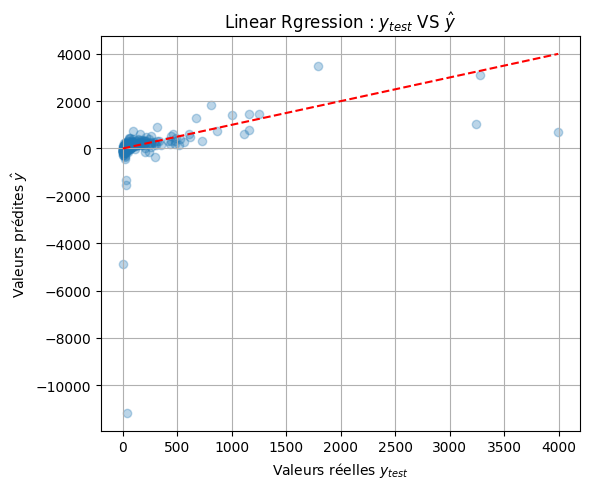

In [88]:
# 1 Modèle de régression linéaire (target continue)
# préparation de data
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=True,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

# initialisation du modèle
reg = LinearRegression()

# entrainement et évaluation du modèle
results_reg, y_hat_reg = train_evaluate_model(reg,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = r'Linear Rgression : $y_{test}$ VS $\hat{y}$')

print(results_reg)

#=========================================================================
# enregistrer la figure
#print(results_rf)
plt.savefig(FIG_DIR / "LinearRegression_prediction_vs_reel_emission.png", dpi=300)
plt.show()

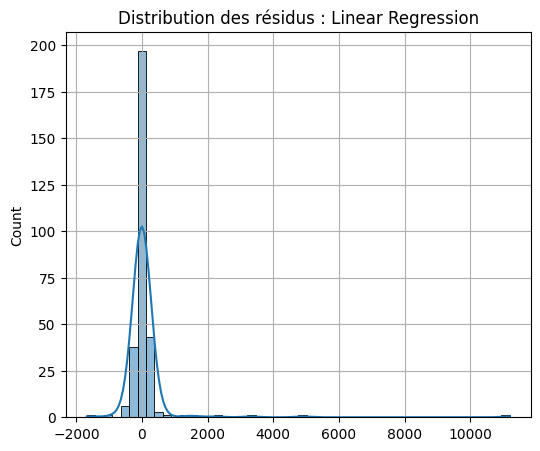

In [89]:
# résidus Linear Regression
residuals = y_test - y_hat_reg
plt.figure(figsize=(6, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Distribution des résidus : Linear Regression")
plt.grid(True)
plt.savefig(FIG_DIR / "LinearRegression_residus_emission.png", dpi=300)
plt.show()

#### 2. Random Forest

`RandomizedSearchCV` (50 tirages, 5 plis) puis `GridSearchCV` resserrée autour du meilleur point.

In [90]:
# 2- Modèle de régression RandomForestRegressor

#=========================================================================
# préparation de data
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=False,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

#=========================================================================
# paramètre à varier
parameters_highLevel = {'max_depth':np.arange(2, 35, 5),
                        'n_estimators': np.arange(100,500,100),
                        'min_samples_leaf':np.arange(1,6),
                        'min_samples_split':np.arange(3,10,2),
                        'max_features':["sqrt", "log2", 0.3, 0.5]}

#=========================================================================
# initialisation du modèle
rf = RandomForestRegressor(random_state=42)

#=========================================================================
# randomized Grid search
rSearch = RandomizedSearchCV(rf, 
                         param_distributions=parameters_highLevel, 
                         cv = 5, 
                         scoring={'r2': 'r2',
                                  'rmse': 'neg_root_mean_squared_error',
                                  'mae': 'neg_mean_absolute_error'}, 
                         n_iter=50,
                         random_state = 42,
                         verbose = 1,
                         refit='rmse')

#=========================================================================
# train model
rSearch.fit(X_train, y_train)

print("Best params (RandomizedSearch):",rSearch.best_params_)
print("Best CV score:", rSearch.best_score_)

#=========================================================================
# best parameters & best model
best_params =rSearch.best_params_
best_model = rSearch.best_estimator_

#=========================================================================
# Construction d'une grille autour de best parameters 
rf_param_grid = {}

for param, value in best_params.items():
    if isinstance(value, numbers.Integral):
        rf_param_grid[param] = grid_around_best(value,2)
    else:
        # paramètres catégoriels (sqrt, log2, None, etc.)
        rf_param_grid[param] = [value]
        
print("Grille autour de Best params (RandomizedSearch):",rf_param_grid)

parameters_lowLevel = rf_param_grid

#=========================================================================
# Grid search
gSearch = GridSearchCV(best_model, parameters_lowLevel, 
                   cv = 5, 
                   scoring={'r2': 'r2',
                            'rmse': 'neg_root_mean_squared_error',
                            'mae': 'neg_mean_absolute_error'}, 
                   verbose = 1,
                   refit='rmse')

#=========================================================================
# train model
gSearch.fit(X_train, y_train)
gSearch.best_params_

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'n_estimators': np.int64(300), 'min_samples_split': np.int64(3), 'min_samples_leaf': np.int64(1), 'max_features': 0.3, 'max_depth': np.int64(22)}
Best CV score: -513.9382115117951
Grille autour de Best params (RandomizedSearch): {'n_estimators': array([298, 299, 300, 301, 302]), 'min_samples_split': array([1, 2, 3, 4, 5]), 'min_samples_leaf': array([1, 2, 3]), 'max_features': [0.3], 'max_depth': array([20, 21, 22, 23, 24])}
Fitting 5 folds for each of 375 candidates, totalling 1875 fits


c:\Users\faiza\Formation_IA\Projet3_mission\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
375 fits failed out of a total of 1875.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
375 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\faiza\Formation_IA\Projet3_mission\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\faiza\Formation_IA\Projet3_mission\.venv\Lib\site-packages\sklearn\base.py", line 1329, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\faiza\F

{'max_depth': np.int64(20),
 'max_features': 0.3,
 'min_samples_leaf': np.int64(1),
 'min_samples_split': np.int64(3),
 'n_estimators': np.int64(302)}

{'model': RandomForestRegressor(max_depth=np.int64(20), max_features=0.3,
                      min_samples_leaf=np.int64(1),
                      min_samples_split=np.int64(3), n_estimators=np.int64(302),
                      random_state=42), 'R2_train': 0.8622004633488686, 'R2_test': 0.6047358428768119, 'RMSE': 253.90561088398707, 'MAE': 91.69331736465332}


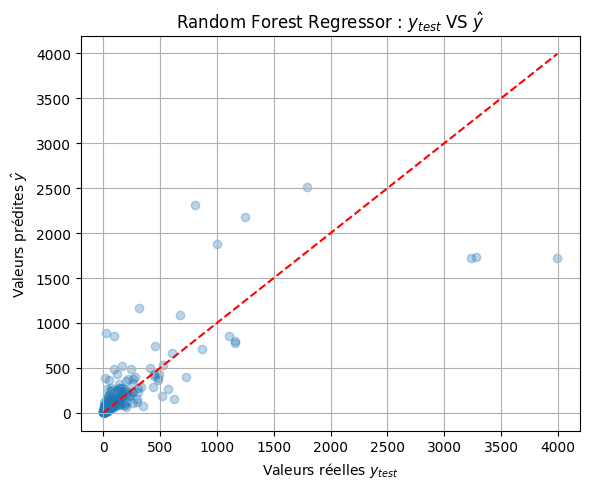

In [91]:
# nouveau best model
best_model_rf = gSearch.best_estimator_
gSearch.best_score_

#=========================================================================
# entrainement et évaluation du modèle
results_rf, y_hat_rf = train_evaluate_model(best_model_rf,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = r'Random Forest Regressor : $y_{test}$ VS $\hat{y}$')

#=========================================================================
# enregistrer la figure
print(results_rf)
plt.savefig(FIG_DIR / "RandomForestRegressor_prediction_vs_reel_emission.png", dpi=300)
plt.show()

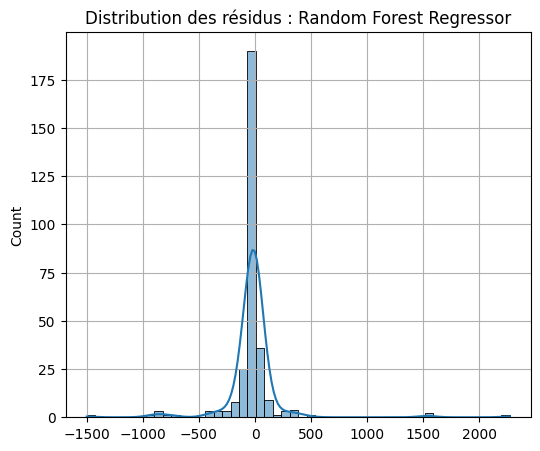

In [92]:
# résidus Random Forest Regressor
residuals = y_test - y_hat_rf
plt.figure(figsize=(6, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Distribution des résidus : Random Forest Regressor")
plt.grid(True)
plt.savefig(FIG_DIR / "RandomForest_residus_emission.png", dpi=300)
plt.show()

#### 3. SVR

Variables et cible mises à l'échelle, le noyau faisant partie des hyperparamètres explorés.

In [93]:
# 3- Modèle SVR

#=========================================================================
# préparation de data
X_train, X_test, y_train, y_test,_,scaler_y = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=True,
                                                scale_y=True,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

#=========================================================================
# paramètre à varier
parameters_highLevel_SVR = {'kernel':['linear', 'poly', 'rbf', 'sigmoid'],# 'precomputed'],
                        'degree': np.arange(2,10,1),
                        'gamma':loguniform(1e-4, 10),
                        'C':loguniform(1e-2, 1e4),
                        'epsilon':loguniform(1e-4, 1.0)}

#=========================================================================
# initialisation du modèle
svr = SVR()

#=========================================================================
# randomized Grid search
rSearch_SVR = RandomizedSearchCV(svr, 
                                 param_distributions=parameters_highLevel_SVR, 
                                 cv = 5, 
                                 scoring={'r2': 'r2',
                                     'rmse': 'neg_root_mean_squared_error',
                                      'mae': 'neg_mean_absolute_error'}, 
                                 n_iter=50,
                                 random_state = 42,
                                 verbose = 1,
                                 refit='rmse')

#=========================================================================
# train model
rSearch_SVR.fit(X_train, y_train)

print("Best params (RandomizedSearch):",rSearch_SVR.best_params_)
print("Best CV score:", rSearch_SVR.best_score_)

#=========================================================================
# best parameters & best model
best_params_SVR =rSearch_SVR.best_params_
best_model_SVR = rSearch_SVR.best_estimator_

#=========================================================================
# Construction d'une grille autour de best parameters 
SVR_param_grid = {}

for param, value in best_params_SVR.items():
    if isinstance(value, numbers.Integral):
        SVR_param_grid[param] = grid_around_best(value,2)
    else:
        # paramètres catégoriels (sqrt, log2, None, etc.)
        SVR_param_grid[param] = [value]
        
print("Grille autour de Best params (RandomizedSearch):",SVR_param_grid)

parameters_lowLevel_SVR = SVR_param_grid

#=========================================================================
# Grid search
gSearch_SVR = GridSearchCV(best_model_SVR, parameters_lowLevel_SVR, 
                   cv = 5, 
                   scoring={'r2': 'r2',
                            'rmse': 'neg_root_mean_squared_error',
                            'mae': 'neg_mean_absolute_error'}, 
                   verbose = 1,
                   refit='rmse')

#=========================================================================
# train model
gSearch_SVR.fit(X_train, y_train)
gSearch_SVR.best_params_

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'C': np.float64(11.818390883060228), 'degree': np.int64(4), 'epsilon': np.float64(0.0024812124357486915), 'gamma': np.float64(0.0003026096376086027), 'kernel': 'linear'}
Best CV score: -0.027403874934704964
Grille autour de Best params (RandomizedSearch): {'C': [np.float64(11.818390883060228)], 'degree': array([2, 3, 4, 5, 6]), 'epsilon': [np.float64(0.0024812124357486915)], 'gamma': [np.float64(0.0003026096376086027)], 'kernel': ['linear']}
Fitting 5 folds for each of 5 candidates, totalling 25 fits


{'C': np.float64(11.818390883060228),
 'degree': np.int64(2),
 'epsilon': np.float64(0.0024812124357486915),
 'gamma': np.float64(0.0003026096376086027),
 'kernel': 'linear'}

{'model': SVR(C=np.float64(11.818390883060228), degree=np.int64(2),
    epsilon=np.float64(0.0024812124357486915),
    gamma=np.float64(0.0003026096376086027), kernel='linear'), 'R2_train': 0.45408040814129347, 'R2_test': -0.01469007062447747, 'RMSE': 406.81343444318077, 'MAE': 120.29386986439872}


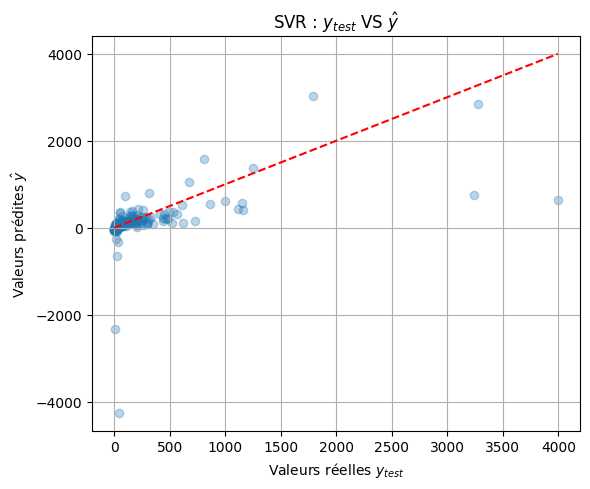

In [94]:
# nouveau best model
best_model_SVR = gSearch_SVR.best_estimator_
gSearch_SVR.best_score_

#=========================================================================
# entrainement et évaluation du modèle
results_SVR, y_hat_SVR = train_evaluate_model(best_model_SVR,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=scaler_y,
                                   plot=True,
                                   title = r'SVR : $y_{test}$ VS $\hat{y}$')

print(results_SVR)

#=========================================================================
# enregistrer la figure
plt.savefig(FIG_DIR / "SVR_prediction_vs_reel_emission.png", dpi=300)
plt.show()

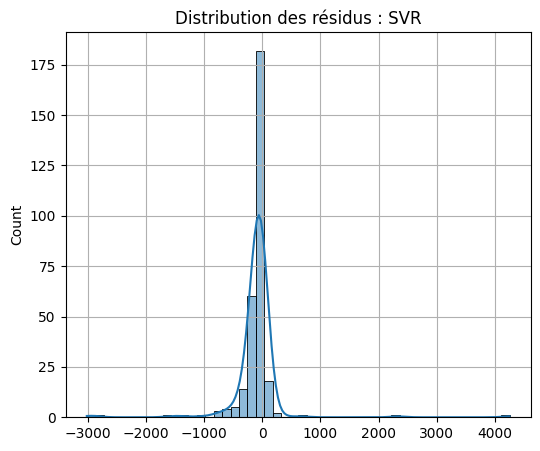

In [95]:
# résidus SVR
residuals = y_test - y_hat_SVR
plt.figure(figsize=(6, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Distribution des résidus : SVR")
plt.grid(True)
plt.savefig(FIG_DIR / "SVR_residus_distribution_emission.png", dpi=300)
plt.show()

#### 4. Gradient Boosting

Cible transformée en `log1p` pour atténuer l'asymétrie de sa distribution.

In [96]:
# 4- Modèle de régression GradientBoostingRegressor

#=========================================================================
# préparation de data
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=False,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

#=========================================================================
# Transformation de y
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)


#=========================================================================
# paramètre à varier
parameters_highLevel_gb = {'n_estimators': np.arange(100, 800,50),
                           'learning_rate': uniform(0.01, 0.19),   
                           'max_depth': np.arange(2, 6),
                           'subsample': uniform(0.6, 0.4),         
                           'min_samples_leaf': np.arange(1, 20,2)}


#=========================================================================
# initialisation du modèle
gb = GradientBoostingRegressor(random_state=42)

#=========================================================================
# randomized Grid search
rSearch_gb = RandomizedSearchCV(gb, 
                                 param_distributions=parameters_highLevel_gb, 
                                 cv = 5, 
                                 scoring={'r2': 'r2',
                                     'rmse': 'neg_root_mean_squared_error',
                                      'mae': 'neg_mean_absolute_error'}, 
                                 n_iter=50,
                                 random_state = 42,
                                 verbose = 1,
                                 refit='rmse')

#=========================================================================
# train model
rSearch_gb.fit(X_train, y_train_log)

print("Best params (RandomizedSearch):",rSearch_gb.best_params_)
print("Best CV score:", rSearch_gb.best_score_)


#=========================================================================
# best parameters & best model
best_params_gb =rSearch_gb.best_params_
best_model_gb = rSearch_gb.best_estimator_

#=========================================================================
# Construction d'une grille autour de best parameters 
gb_param_grid = {}

for param, value in best_params_gb.items():
    if isinstance(value, numbers.Integral):
        gb_param_grid[param] = grid_around_best(value,2)
    else:
        # paramètres catégoriels (sqrt, log2, None, etc.)
        gb_param_grid[param] = [value]
        
print("Grille autour de Best params (RandomizedSearch):",gb_param_grid)

parameters_lowLevel_gb = gb_param_grid

#=========================================================================
# Grid search
gSearch_gb = GridSearchCV(best_model_gb, parameters_lowLevel_gb, 
                   cv = 5, 
                   scoring={'r2': 'r2',
                            'rmse': 'neg_root_mean_squared_error',
                            'mae': 'neg_mean_absolute_error'}, 
                   verbose = 1,
                   refit='rmse')

#=========================================================================
# train model
gSearch_gb.fit(X_train, y_train_log)
gSearch_gb.best_params_

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'learning_rate': np.float64(0.060688392712304154), 'max_depth': np.int64(3), 'min_samples_leaf': np.int64(3), 'n_estimators': np.int64(650), 'subsample': np.float64(0.6205915004999957)}
Best CV score: -0.6344009415449542
Grille autour de Best params (RandomizedSearch): {'learning_rate': [np.float64(0.060688392712304154)], 'max_depth': array([1, 2, 3, 4, 5]), 'min_samples_leaf': array([1, 2, 3, 4, 5]), 'n_estimators': array([648, 649, 650, 651, 652]), 'subsample': [np.float64(0.6205915004999957)]}
Fitting 5 folds for each of 125 candidates, totalling 625 fits


{'learning_rate': np.float64(0.060688392712304154),
 'max_depth': np.int64(3),
 'min_samples_leaf': np.int64(5),
 'n_estimators': np.int64(648),
 'subsample': np.float64(0.6205915004999957)}

{'model': GradientBoostingRegressor(learning_rate=np.float64(0.060688392712304154),
                          max_depth=np.int64(3), min_samples_leaf=np.int64(5),
                          n_estimators=np.int64(648), random_state=42,
                          subsample=np.float64(0.6205915004999957)), 'R2_train': 0.8779094097598049, 'R2_test': 0.8403001409689163, 'RMSE': 161.39157044048102, 'MAE': 55.85923906060873}


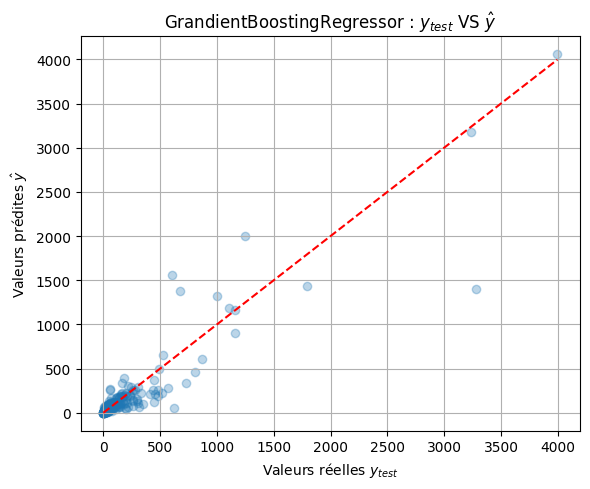

In [97]:
# nouveau best model
best_model_gb = gSearch_gb.best_estimator_
gSearch_gb.best_score_

#=========================================================================
# entrainement et évaluation du modèle
results_gb, y_hat_gb = train_evaluate_model(best_model_gb,
                                   X_train,
                                   X_test,
                                   y_train_log,
                                   y_test_log,
                                   scaler_y=np.log1p,
                                   plot=True,
                                   title = r'GrandientBoostingRegressor : $y_{test}$ VS $\hat{y}$')

print(results_gb)

#=========================================================================
# enregistrer la figure
plt.savefig(FIG_DIR / "GradientBoosting_prediction_vs_reel_emission.png", dpi=300)
plt.show()

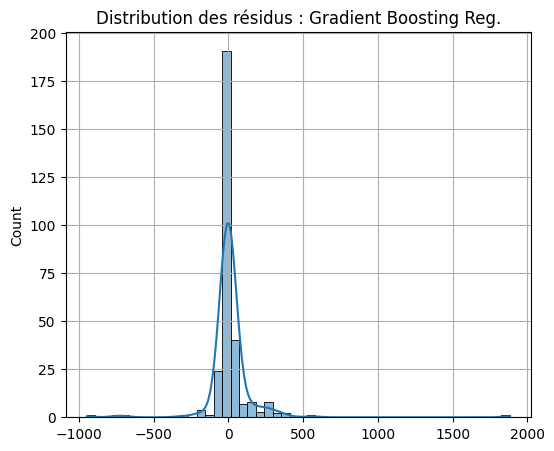

In [98]:
# résidus Gradient Boosting Regressor
residuals = y_test - y_hat_gb
plt.figure(figsize=(6, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Distribution des résidus : Gradient Boosting Reg.")
plt.grid(True)
plt.savefig(FIG_DIR / "GradientBoosting_residus_distribution_emission.png", dpi=300)
plt.show()

#### 5. XGBoost

In [99]:
# 5- Modèle XGBoost

#=========================================================================
# préparation de data
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=False,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

#=========================================================================
# paramètre à varier
parameters_highLevel_xgb = {
    "n_estimators": randint(300, 1200),
    "max_depth": randint(2, 10),
    "learning_rate": uniform(0.01, 0.19),     
    "subsample": uniform(0.6, 0.4),           
    "colsample_bytree": uniform(0.6, 0.4),   
    "min_child_weight": randint(1, 10),
    "reg_alpha": uniform(0.0, 1.0),
    "reg_lambda": uniform(0.5, 2.0)}


#=========================================================================
# initialisation du modèle
xgb = XGBRegressor(objective="reg:squarederror",random_state=42,n_jobs=-1)

#=========================================================================
# randomized Grid search
rSearch_xgb = RandomizedSearchCV(xgb, 
                                 param_distributions=parameters_highLevel_xgb, 
                                 cv = 5, 
                                 scoring={'r2': 'r2',
                                     'rmse': 'neg_root_mean_squared_error',
                                      'mae': 'neg_mean_absolute_error'}, 
                                 n_iter=50,
                                 random_state = 42,
                                 verbose = 1,
                                 refit='rmse')

#=========================================================================
# train model
rSearch_xgb.fit(X_train, y_train_log)

print("Best params (RandomizedSearch):",rSearch_xgb.best_params_)
print("Best CV score:", rSearch_xgb.best_score_)


#=========================================================================
# best parameters & best model
best_params_xgb =rSearch_xgb.best_params_
best_model_xgb = rSearch_xgb.best_estimator_

#=========================================================================
# Construction d'une grille autour de best parameters 
xgb_param_grid = {}

for param, value in best_params_xgb.items():
    if isinstance(value, numbers.Integral):
        xgb_param_grid[param] = grid_around_best(value,2)
    else:
        # paramètres catégoriels (sqrt, log2, None, etc.)
        xgb_param_grid[param] = [value]
        
print("Grille autour de Best params (RandomizedSearch):",xgb_param_grid)

parameters_lowLevel_xgb = xgb_param_grid

#=========================================================================
# Grid search
gSearch_xgb = GridSearchCV(best_model_xgb, parameters_lowLevel_xgb, 
                   cv = 5, 
                   scoring={'r2': 'r2',
                            'rmse': 'neg_root_mean_squared_error',
                            'mae': 'neg_mean_absolute_error'}, 
                   verbose = 1,
                   refit='rmse')

#=========================================================================
# train model
gSearch_xgb.fit(X_train, y_train_log)
gSearch_xgb.best_params_

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'colsample_bytree': np.float64(0.6550083776583973), 'learning_rate': np.float64(0.0748026066995491), 'max_depth': 2, 'min_child_weight': 2, 'n_estimators': 450, 'reg_alpha': np.float64(0.5414479738275658), 'reg_lambda': np.float64(1.8915687986901644), 'subsample': np.float64(0.6914200087189198)}
Best CV score: -0.6376592913662079
Grille autour de Best params (RandomizedSearch): {'colsample_bytree': [np.float64(0.6550083776583973)], 'learning_rate': [np.float64(0.0748026066995491)], 'max_depth': array([1, 2, 3, 4]), 'min_child_weight': array([1, 2, 3, 4]), 'n_estimators': array([448, 449, 450, 451, 452]), 'reg_alpha': [np.float64(0.5414479738275658)], 'reg_lambda': [np.float64(1.8915687986901644)], 'subsample': [np.float64(0.6914200087189198)]}
Fitting 5 folds for each of 80 candidates, totalling 400 fits


{'colsample_bytree': np.float64(0.6550083776583973),
 'learning_rate': np.float64(0.0748026066995491),
 'max_depth': np.int64(3),
 'min_child_weight': np.int64(2),
 'n_estimators': np.int64(449),
 'reg_alpha': np.float64(0.5414479738275658),
 'reg_lambda': np.float64(1.8915687986901644),
 'subsample': np.float64(0.6914200087189198)}

{'model': GradientBoostingRegressor(learning_rate=np.float64(0.060688392712304154),
                          max_depth=np.int64(3), min_samples_leaf=np.int64(5),
                          n_estimators=np.int64(648), random_state=42,
                          subsample=np.float64(0.6205915004999957)), 'R2_train': 0.8779094097598049, 'R2_test': 0.8403001409689163, 'RMSE': 161.39157044048102, 'MAE': 55.85923906060873}


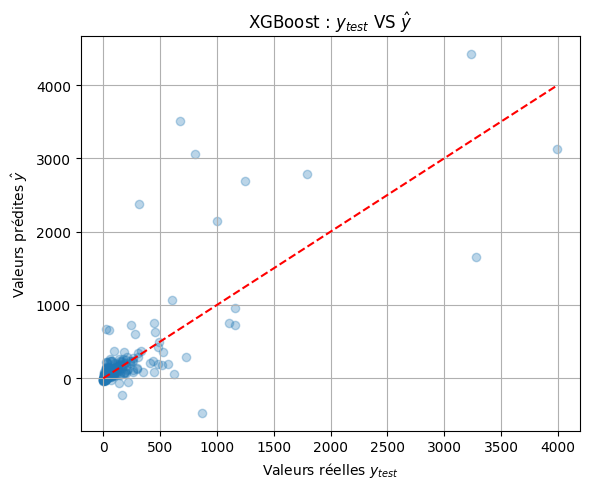

In [100]:
# nouveau best model
best_model_xgb = gSearch_xgb.best_estimator_
gSearch_xgb.best_score_

#=========================================================================
# entrainement et évaluation du modèle
results_xgb, y_hat_xgb = train_evaluate_model(best_model_xgb,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = r'XGBoost : $y_{test}$ VS $\hat{y}$')

print(results_gb)

#=========================================================================
# enregistrer la figure
plt.savefig(FIG_DIR / "XGBoost_prediction_vs_reel_emission.png", dpi=300)
plt.show()

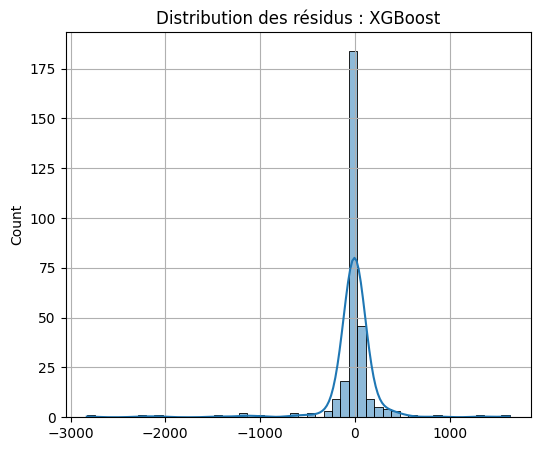

In [101]:
# résidus Gradient Boosting Regressor
residuals = y_test - y_hat_xgb
plt.figure(figsize=(6, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Distribution des résidus : XGBoost")
plt.grid(True)
plt.savefig(FIG_DIR / "XGBoost_residus_distribution_emission.png", dpi=300)
plt.show()

### Optimisation et interprétation du modèle

Le meilleur modèle est repris pour identifier les variables qui pèsent le plus sur la prédiction.

Importance des variables du Random Forest optimisé.

In [102]:
# optimisation des modèles RandomForestRegressor et SVR faite en ament

# feature importance pour Rnadom Forest Regressor
feature_importances = pd.Series(best_model_rf.feature_importances_,
                                index=X_train.columns).sort_values(ascending=False)

feature_importances

PropertyGFATotal                                         0.339317
PropertyUseType_Hospital (General Medical & Surgical)    0.121631
PropertyUseType_Laboratory                               0.080484
ElectricityPercentage                                    0.076121
OtherEnergyPercentage                                    0.063338
                                                           ...   
PropertyUseType_Enclosed Mall                            0.000000
PropertyUseType_Residential Care Facility                0.000000
PropertyUseType_Wholesale Club/Supercenter               0.000000
PropertyUseType_Small- and Mid-Sized Office              0.000000
PropertyUseType_Swimming Pool                            0.000000
Length: 76, dtype: float64

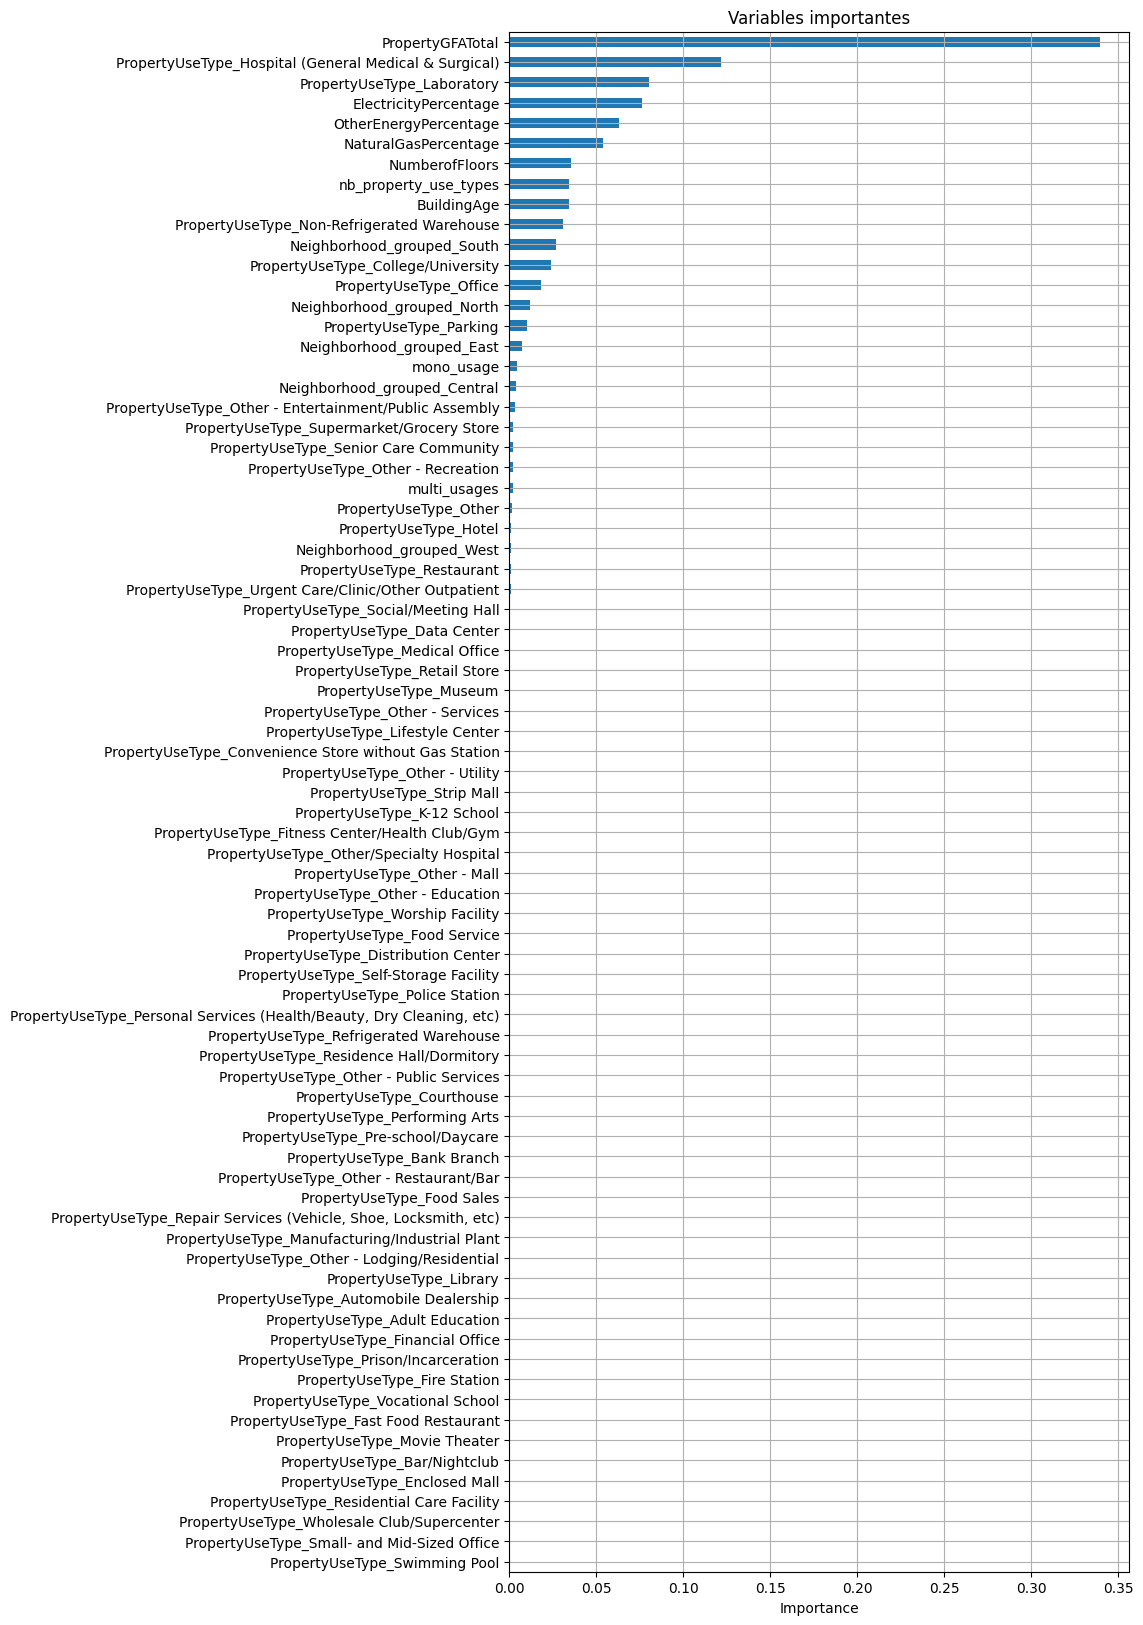

In [103]:
plt.figure(figsize=(8,20))
feature_importances.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Variables importantes")
plt.xlabel("Importance")
plt.grid(True)
plt.savefig(FIG_DIR / "features_importance_rf_emission.png", dpi=300, bbox_inches="tight")
plt.show()

Regroupement des modalités one-hot par famille : sans cela, l'importance se dilue sur les 68 colonnes de type d'usage.

In [104]:
# regrouper les features comme avant le mapping

grouped_importances = (feature_importances.reset_index().rename(columns={'index': 'feature', 0: 'importance'}))

grouped_importances['group'] = grouped_importances['feature'].apply(group_feature_name)

grouped_importances_sum = (grouped_importances.groupby('group')['importance'].sum().sort_values(ascending=False))

grouped_importances_sum

group
PropertyGFATotal         0.339317
PropertyUseType          0.304795
EnergySource             0.193455
Neighborhood_grouped     0.051690
NumberofFloors           0.035557
nb_property_use_types    0.034477
BuildingAge              0.034204
usage_type               0.006505
Name: importance, dtype: float64

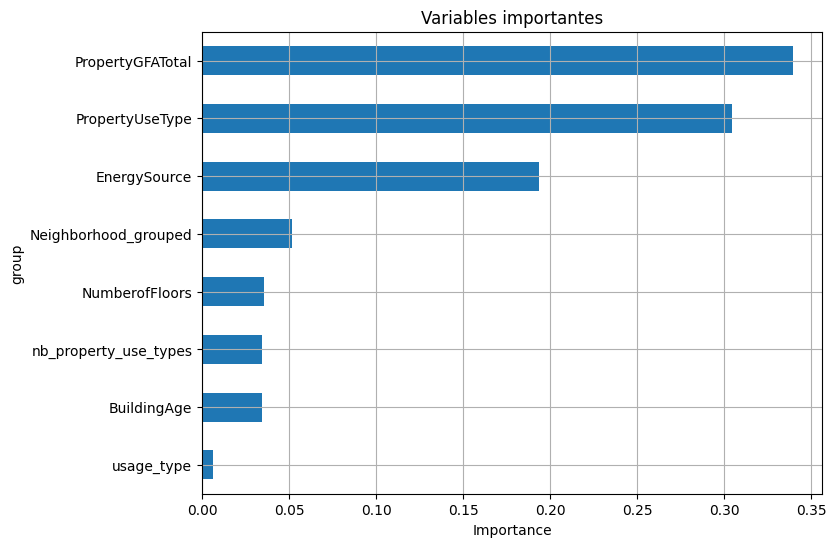

In [105]:
plt.figure(figsize=(8,6))
grouped_importances_sum.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Variables importantes")
plt.xlabel("Importance")
plt.grid(True)
plt.savefig(FIG_DIR / "features_importance_grouped_rf_emission.png", dpi=300, bbox_inches="tight")
plt.show()

Permutation importance, mesure complémentaire calculée sur le jeu de test.

In [106]:
# Permutation importance
r = permutation_importance(
    best_model_rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="neg_root_mean_squared_error")

#perm_importances = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)

#perm_importances

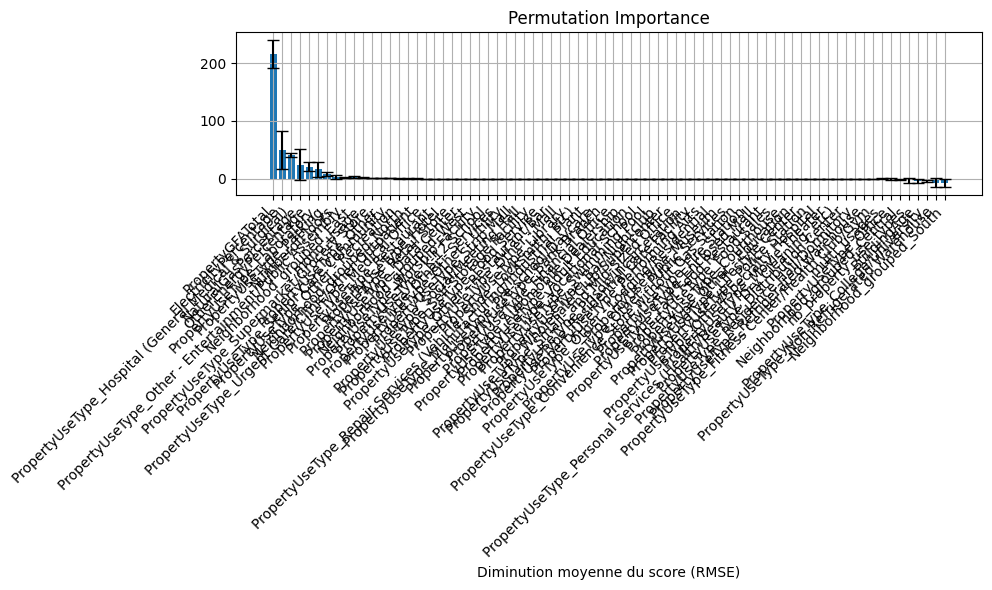

In [107]:
perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": r.importances_mean,
    "importance_std": r.importances_std
}).sort_values("importance_mean", ascending=False)

plt.figure(figsize=(10,6))

top_k = len(X_test.columns)
plt.bar(perm_df["feature"].head(top_k),
        perm_df["importance_mean"].head(top_k),
        yerr=perm_df["importance_std"].head(top_k),
        capsize=4)


plt.xlabel("Diminution moyenne du score (RMSE)")
plt.title("Permutation Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.grid(True)
plt.savefig(FIG_DIR / "permutation_importance_rf.png", dpi=300, bbox_inches="tight")
plt.show()

---

## Conclusions

**Cible :** `TotalGHGEmissions` — émissions totales de gaz à effet de serre (tonnes CO₂e).

### Démarche

Périmètre, nettoyage et feature engineering sont repris **à l'identique** du notebook 1,
seule la cible change. Le périmètre final compte **1 480 bâtiments × 76 variables** — un de
plus que le notebook 1, le filtre sur les relevés manquants ne portant pas sur la même
colonne.

Ce parallélisme est volontaire : il rend les deux modélisations directement comparables et
permet de distinguer ce qui relève de la **quantité d'énergie consommée** de ce qui relève
du **contenu carbone** de cette énergie.

### Comparaison des modèles

| Modèle | R² train | R² test | RMSE (t CO₂e) | MAE (t CO₂e) |
|---|---|---|---|---|
| LinearRegression | 0,490 | **−2,741** | 781,15 | 203,51 |
| SVR (noyau linéaire) | 0,454 | −0,015 | 406,81 | 120,29 |
| RandomForestRegressor | 0,862 | 0,605 | 253,91 | 91,69 |
| **GradientBoostingRegressor** | **0,878** | **0,840** | **161,39** | **55,86** |

Modèle retenu : `learning_rate=0,061`, `max_depth=3`, `min_samples_leaf=5`,
`n_estimators=648`, `subsample=0,621`.

**La régression linéaire est inutilisable** : un R² test de −2,741 contre 0,490 en
apprentissage signifie des prédictions près de quatre fois plus mauvaises que la simple
moyenne de la cible. Cet effondrement est la signature d'une extrapolation linéaire sur une
cible fortement asymétrique — quelques bâtiments très émetteurs du jeu de test sortent du
domaine appris. Le SVR, borné par son `epsilon`, s'arrête à −0,015, soit l'équivalent d'une
prédiction constante.

**Le GradientBoosting domine nettement** : 0,840 de R² test, soit 0,235 point au-dessus de la
forêt aléatoire, là où l'écart n'était que de 0,012 sur la consommation. Sa MAE est
inférieure de 39 % et son écart train/test quasi nul (0,878 → 0,840) : le modèle est à la
fois le plus performant et le mieux calibré de la comparaison.

### Variables déterminantes

| Famille de variables | Importance | Rappel notebook 1 |
|---|---|---|
| `PropertyGFATotal` (surface totale) | **0,339** | 0,287 |
| `PropertyUseType` (profil d'usage) | 0,305 | 0,368 |
| `EnergySource` (mix énergétique) | **0,193** | 0,169 |
| `Neighborhood_grouped` | 0,052 | 0,044 |
| `NumberofFloors` | 0,036 | 0,051 |
| `nb_property_use_types` | 0,034 | 0,041 |
| `BuildingAge` | 0,034 | 0,034 |
| `usage_type` (mono / multi) | 0,007 | 0,006 |

**La hiérarchie s'inverse par rapport à la consommation** : la surface devient le premier
facteur (0,339) et passe devant l'usage (0,305), tandis que le mix énergétique gagne du
terrain (0,193). Les émissions suivent d'abord le **volume** d'énergie — donc la surface —
pondéré par le contenu carbone de cette énergie. L'usage reste déterminant
(`PropertyUseType_Hospital` 0,122, `PropertyUseType_Laboratory` 0,080) mais agit davantage
comme proxy de l'intensité d'usage que comme facteur carbone propre.

### Réserves sur les résultats

- **Le R² de 0,840 est surestimé par une fuite de données.** Les émissions se prédisent ici
  mieux que la consommation (0,840 contre 0,735) parce que le mix énergétique figure dans les
  variables sous forme de parts calculées à partir des consommations mesurées. À Seattle
  l'électricité est largement hydraulique et peu carbonée, le gaz naturel fortement carboné :
  la part de gaz détermine les émissions presque par construction. Ce n'est donc pas un
  enseignement métier mais un artefact — ces parts ne sont pas connues au moment de la
  prédiction. Le levier « électrifier le chauffage » reste vrai physiquement, mais il ne se
  déduit pas de ces importances.
- **XGBoost non exploitable en l'état.** Le modèle a bien été entraîné et optimisé
  (`colsample_bytree=0,655`, `learning_rate=0,075`, `max_depth=3`, `n_estimators=449`,
  `subsample=0,691`), mais la cellule d'évaluation affiche `results_gb` au lieu de
  `results_xgb` — même erreur que dans le notebook 1. Aucune métrique XGBoost n'a donc été
  restituée pour cette cible, et les valeurs XGBoost des graphiques de comparaison dupliquent
  celles du GradientBoosting. Corriger l'appel à `print` suffit à les obtenir.
- **Fort déséquilibre de la cible** : les gros émetteurs sont rares et portent l'essentiel de
  l'enjeu, alors que les métriques globales sont dominées par la masse des petits bâtiments.
  Un R² de 0,840 ne garantit pas la fiabilité sur le haut de la distribution.
- **Métriques issues d'un unique découpage train/test** (`random_state=42`), d'autant plus à
  confirmer par validation croisée répétée que les modèles linéaires se révèlent ici très
  sensibles au découpage.

**Suites** : remplacer les parts de mix par des indicateurs de présence de source
(`HasElectricity`, `HasNaturalGas`, `HasSteam`) et réexécuter les deux notebooks ; comparer
ensuite le modèle appris au calcul direct par facteurs d'émission
(consommation × facteur par source), plus juste et plus transparent là où le détail du mix
est connu ; évaluer les performances par tranche de surface pour documenter la fiabilité sur
les gros émetteurs.